# Cómo ver los resultados en Google Colab

Este notebook se publica con las salidas de una ejecución integral ya guardadas. Al abrirlo, puedes desplazarte por las celdas para ver tablas, métricas y gráficas sin ejecutar nada. Para la demostración visual, ve a **“Demostración final: así A* Balanced evita el tramo de alta accidentalidad”** al final: allí están el mapa comparativo interactivo y el resumen del caso real. En el mapa, azul identifica A* tradicional, naranja A* Balanced y rojo el tramo de alto riesgo evitado; la leyenda permite mostrar u ocultar cada capa.

# Waze IA - correccion con Node y Tree


La solucion conserva el mapa real y el costo compuesto, pero representa cada estado como un objeto `OSMRouteNode(Node)` y ejecuta A* mediante `OSMRouteTree(Tree)`.

## 1. Importaciones y mapa

La red se descarga como un grafo dirigido para vehículos. NetworkX solo se usa para representar y consultar el grafo: la búsqueda de rutas se implementa más adelante con A*.


In [1]:
# Preparación portable: Colab clona e instala el repositorio; local usa la raíz del checkout.
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

REPOSITORY_URL = "https://github.com/santiago-zuluaga/trabajo-waze.git"

def _is_project_root(candidate):
    return (candidate / "pyproject.toml").is_file() and (candidate / "waze_accidents.py").is_file()

def _find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if _is_project_root(candidate):
            return candidate.resolve()
    spec = importlib.util.find_spec("waze_accidents")
    if spec and spec.origin:
        module_root = Path(spec.origin).resolve().parent
        if _is_project_root(module_root):
            return module_root
    return None

IN_COLAB = bool(os.environ.get("COLAB_RELEASE_TAG"))
if IN_COLAB:
    PROJECT_ROOT = Path("/content/trabajo-waze")
    if not _is_project_root(PROJECT_ROOT):
        if PROJECT_ROOT.exists():
            raise RuntimeError(f"La carpeta {PROJECT_ROOT} existe, pero no contiene el checkout esperado. Renómbrala o elimínala y vuelve a ejecutar.")
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL, str(PROJECT_ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-e", f"{PROJECT_ROOT}[notebook]"], check=True)
else:
    PROJECT_ROOT = _find_project_root()
    if PROJECT_ROOT is None:
        raise RuntimeError("No se encontró la raíz del proyecto. Abre el notebook desde el checkout o instala trabajo-waze en este entorno.")

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
print(f"Proyecto: {PROJECT_ROOT} | Entorno: {'Google Colab' if IN_COLAB else 'Jupyter local'}")

from pathlib import Path
from urllib.parse import urlencode
import heapq
import math
import time

import geopandas as gpd
import ipywidgets as widgets
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
import plotly.graph_objects as go
from IPython.display import HTML, clear_output, display
from shapely.geometry import LineString
from waze_accidents import associate_and_aggregate, edge_risk, load_incidents
from waze_communes import (
    assign_incidents_to_communes,
    build_commune_frequency,
    download_official_admin_units,
    load_official_admin_units,
    map_edges_to_communes,
)

pd.set_option("display.max_columns", None)


Proyecto: C:\Users\santi\Universidad\EIA\IA\Wazenuevo\trabajo-waze | Entorno: Jupyter local


In [2]:

from pathlib import Path
import gzip
import shutil

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("No se encontró la raíz del proyecto")
    PROJECT_ROOT = PROJECT_ROOT.parent

osm_gz = PROJECT_ROOT / "data" / "raw" / "medellin_waze.osm.gz"
osm_file = PROJECT_ROOT / "data" / "raw" / "medellin_waze.osm"

if not osm_file.is_file():
    if not osm_gz.is_file():
        raise FileNotFoundError(f"No se encuentra el archivo OSM: {osm_gz}")
    with gzip.open(osm_gz, "rb") as source, open(osm_file, "wb") as destination:
        shutil.copyfileobj(source, destination)
    print("Archivo OSM descomprimido correctamente")
else:
    print("Se reutiliza el archivo OSM local existente:", osm_file)
print(f"Ubicación: {osm_file}")
print(f"Tamaño: {osm_file.stat().st_size / (1024**2):.2f} MB")


Se reutiliza el archivo OSM local existente: C:\Users\santi\Universidad\EIA\IA\Wazenuevo\trabajo-waze\data\raw\medellin_waze.osm
Ubicación: C:\Users\santi\Universidad\EIA\IA\Wazenuevo\trabajo-waze\data\raw\medellin_waze.osm
Tamaño: 255.22 MB


Red vial dirigida cargada desde caché válida: C:\Users\santi\Universidad\EIA\IA\Wazenuevo\trabajo-waze\cache\medellin_drive.graphml
Grafo dirigido para automóvil: 153,765 nodos, 285,654 aristas


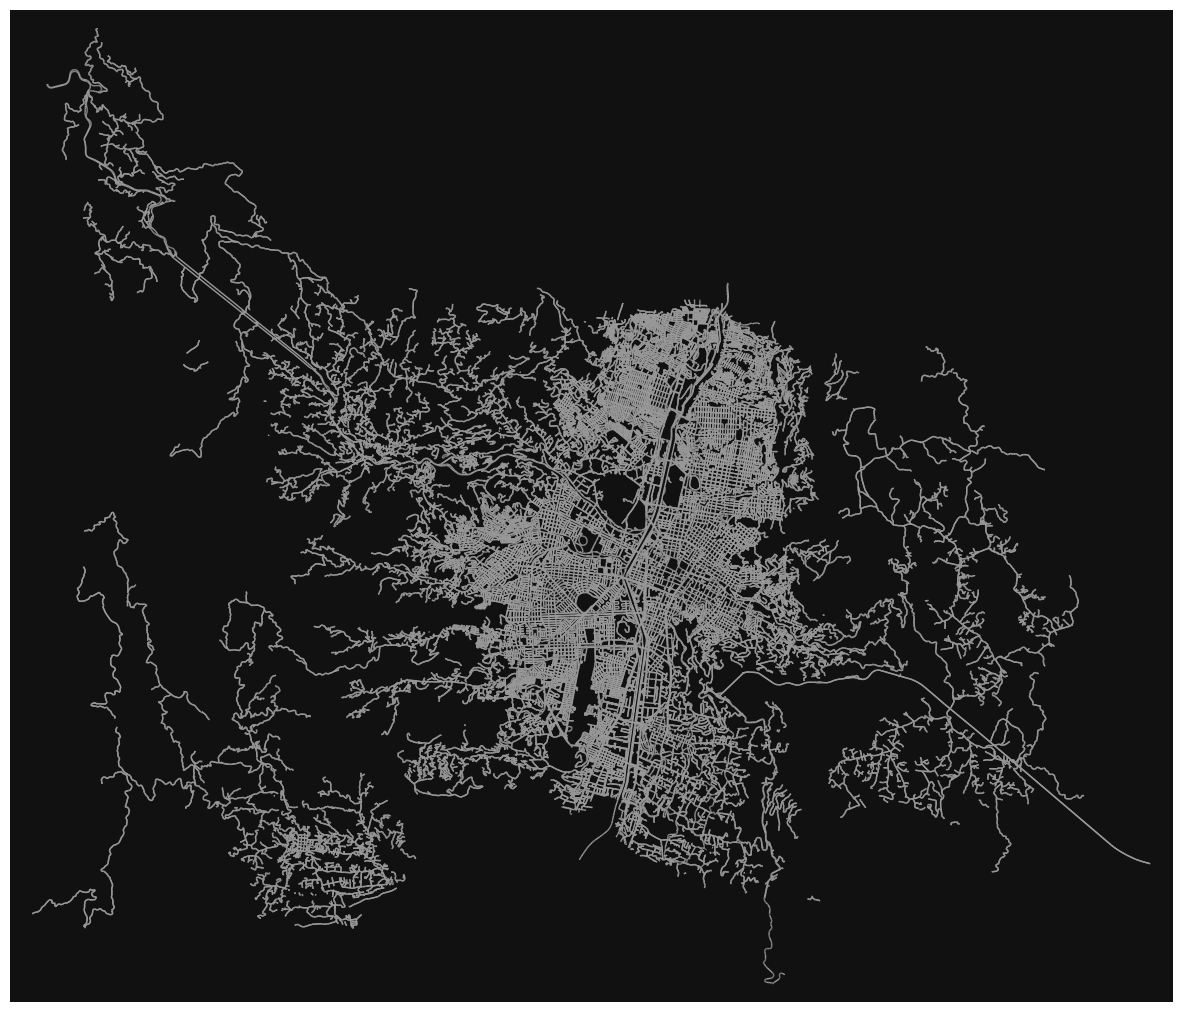

(<Figure size 1500x1500 with 1 Axes>, <Axes: >)

In [3]:
from pathlib import Path
import os
import networkx as nx
import osmnx as ox

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("No se encontró la raíz del proyecto")
    PROJECT_ROOT = PROJECT_ROOT.parent

GRAPH_CACHE_PATH = PROJECT_ROOT / "cache" / "medellin_drive.graphml"
OSM_XML_PATH = PROJECT_ROOT / "data" / "raw" / "medellin_waze.osm"
GRAPH_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)

# Perfil de vías para automóvil acordado para la simulación.
DRIVE_HIGHWAY_SPEEDS = {
    "motorway": 80, "motorway_link": 80, "trunk": 80, "trunk_link": 80,
    "primary": 60, "primary_link": 60,
    "secondary": 50, "secondary_link": 50,
    "tertiary": 50, "tertiary_link": 50,
    "residential": 30, "unclassified": 30, "road": 30,
    "living_street": 20, "service": 20,
}
BLOCKED_ACCESS = {"no", "private", "agricultural", "forestry"}

def _valid_drive_graph(graph):
    if graph is None or len(graph) == 0 or graph.number_of_edges() == 0:
        return False
    return all(
        str(value) in DRIVE_HIGHWAY_SPEEDS
        for _, _, data in graph.edges(data=True)
        for value in (data.get("highway") if isinstance(data.get("highway"), (list, tuple, set)) else [data.get("highway")])
    )

G = None
if GRAPH_CACHE_PATH.is_file() and GRAPH_CACHE_PATH.stat().st_size > 0:
    try:
        cached_graph = ox.load_graphml(GRAPH_CACHE_PATH)
        if _valid_drive_graph(cached_graph):
            G = cached_graph
            print("Red vial dirigida cargada desde caché válida:", GRAPH_CACHE_PATH)
        else:
            print("Caché GraphML vacía o incompatible; se reconstruirá desde el OSM local.")
    except Exception as error:
        print(f"Caché GraphML no válida ({type(error).__name__}); se reconstruirá desde el OSM local.")

if G is None:
    if not OSM_XML_PATH.is_file():
        raise FileNotFoundError(f"No hay caché válida ni OSM local: {OSM_XML_PATH}")
    # Preserve access tags so restrictions can be checked after local parsing.
    ox.settings.useful_tags_way = list(dict.fromkeys(
        [*ox.settings.useful_tags_way, "vehicle", "motor_vehicle", "motorcar"]
    ))
    print("Reconstruyendo red vial desde OSM local; no se consulta Overpass...")
    G = ox.graph_from_xml(OSM_XML_PATH, bidirectional=False, simplify=False, retain_all=True)
    # Remove disallowed edges one node at a time to bound temporary memory use.
    for u in list(G.nodes):
        for _, v, key, data in list(G.out_edges(u, keys=True, data=True)):
            highway = data.get("highway")
            highway_values = highway if isinstance(highway, (list, tuple, set)) else [highway]
            highway_values = [str(value) for value in highway_values if value is not None]
            access_values = [
                str(data.get(tag, "")).strip().lower()
                for tag in ("motorcar", "motor_vehicle", "vehicle", "access")
                if data.get(tag) is not None
            ]
            if not set(highway_values).intersection(DRIVE_HIGHWAY_SPEEDS) or any(
                value in BLOCKED_ACCESS for value in access_values
            ):
                G.remove_edge(u, v, key)
    G.remove_nodes_from(list(nx.isolates(G)))
    if not _valid_drive_graph(G):
        raise RuntimeError("La red vial filtrada quedó vacía o contiene vías no vehiculares.")

    temporary_cache = GRAPH_CACHE_PATH.with_suffix(".graphml.tmp")
    ox.save_graphml(G, temporary_cache)
    # Validate the completed file before atomically replacing the invalid cache.
    validated_graph = ox.load_graphml(temporary_cache)
    if not _valid_drive_graph(validated_graph):
        temporary_cache.unlink(missing_ok=True)
        raise RuntimeError("La caché GraphML recién escrita no pasó la validación.")
    os.replace(temporary_cache, GRAPH_CACHE_PATH)
    G = validated_graph
    print("Caché local válida guardada:", GRAPH_CACHE_PATH)

print(f"Grafo dirigido para automóvil: {len(G):,} nodos, {G.number_of_edges():,} aristas")
ox.plot_graph(G, figsize=(15, 15), node_size=0, show=True, close=True)


## 2. Información del mapa y tiempos de viaje

Se convierten los nodos y aristas a tablas geográficas y se calculan velocidades y tiempos de viaje, igual que en el ejemplo de clase.


In [4]:
hwy_speeds = DRIVE_HIGHWAY_SPEEDS
hwy_speeds

{'motorway': 80,
 'motorway_link': 80,
 'trunk': 80,
 'trunk_link': 80,
 'primary': 60,
 'primary_link': 60,
 'secondary': 50,
 'secondary_link': 50,
 'tertiary': 50,
 'tertiary_link': 50,
 'residential': 30,
 'unclassified': 30,
 'road': 30,
 'living_street': 20,
 'service': 20}

Calcular velocidades, tiempos de viaje y orientaciones

In [5]:
G = ox.add_edge_speeds(G, hwy_speeds=hwy_speeds)
G = ox.add_edge_travel_times(G)
G = ox.add_edge_bearings(G)

In [6]:
gdf_nodes, gdf_edges = ox.graph_to_gdfs(G)
gdf_edges.head()

osmid      highway lanes maxspeed  \
u         v          key                                          
309026269 5483069113 0     28136096    secondary     3       50   
309026271 404910004  0    570316480    secondary     3       50   
309026273 393988726  0     34939944    secondary     3       50   
          5531246241 0    913377168      primary     3      NaN   
309026274 5532356070 0    569672822  residential     1      NaN   

                                        name  oneway  reversed     length  \
u         v          key                                                    
309026269 5483069113 0              Calle 10    True     False  76.702542   
309026271 404910004  0              Calle 10    True     False  42.692226   
309026273 393988726  0              Calle 10    True     False  12.333670   
          5531246241 0    Avenida El Poblado    True     False  11.669436   
309026274 5532356070 0            Carrera 41    True     False   6.880701   

                          speed_kph  travel_time     bearing bridge junction  \
u         v          key                                                       
309026269 5483069113 0         50.0     5.522583  113.422301    NaN      NaN   
309026271 404910004  0         50.0     3.073840  111.513705    NaN      NaN   
309026273 393988726  0         50.0     0.888024  110.365095    NaN      NaN   
          5531246241 0         60.0     0.700166  201.564321    NaN      NaN   
309026274 5532356070 0         30.0     0.825684  202.181493    NaN      NaN   

                         width  ref service area access motor_vehicle tunnel  \
u         v          key                                                       
309026269 5483069113 0     NaN  NaN     NaN  NaN    NaN           NaN    NaN   
309026271 404910004  0     NaN  NaN     NaN  NaN    NaN           NaN    NaN   
309026273 393988726  0     NaN  NaN     NaN  NaN    NaN           NaN    NaN   
          5531246241 0     NaN  NaN     NaN  NaN    NaN           NaN    NaN   
309026274 5532356070 0     NaN  NaN     NaN  NaN    NaN           NaN    NaN   

                         motorcar  \
u         v          key            
309026269 5483069113 0        NaN   
309026271 404910004  0        NaN   
309026273 393988726  0        NaN   
          5531246241 0        NaN   
309026274 5532356070 0        NaN   

                                                                   geometry  
u         v          key                                                     
309026269 5483069113 0    LINESTRING (-75.57393 6.21195, -75.57329 6.21168)  
309026271 404910004  0     LINESTRING (-75.57286 6.21152, -75.5725 6.21138)  
309026273 393988726  0    LINESTRING (-75.57052 6.21062, -75.57042 6.21059)  
          5531246241 0    LINESTRING (-75.57052 6.21062, -75.57056 6.21053)  
309026274 5532356070 0     LINESTRING (-75.56877 6.20997, -75.5688 6.20991)

In [7]:
gdf_edges.explode('highway').groupby('highway')[['length', 'speed_kph', 'travel_time']].mean().round(1)

,length,speed_kph,travel_time
highway,,,
living_street,11.7,20.0,2.1
primary,29.6,55.6,1.9
primary_link,11.9,59.0,0.7
residential,21.2,30.0,2.5
secondary,18.2,45.8,1.5
secondary_link,9.9,48.2,0.8
service,13.6,20.0,2.5
tertiary,19.4,47.1,1.5
tertiary_link,8.1,49.6,0.6


In [8]:
# Dataset oficial local. El archivo crudo no se incluye en Git.
ACCIDENT_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "siniestralidad_medellin.geojson"
ADMIN_UNITS_PATH = PROJECT_ROOT / "data" / "processed" / "medellin_admin_units.geojson"
ACCIDENT_COUNTS = {}
ACCIDENT_RISK = {}
ACCIDENT_COMMUNE_COUNTS = {}
ACCIDENT_COMMUNE_RISK = {}
ACCIDENT_COMMUNE_BY_EDGE = {}
ACCIDENT_COMMUNE_NAMES = {}
ACCIDENT_LOAD_REPORT = None
ACCIDENT_ASSOCIATION_STATS = None
DATA_MODE = "unavailable"
DEMO_ZONE_BY_EDGE = {}
DEMO_ZONE_NAMES = {}
DEMO_COUNTS = {}
DEMO_RISK = {}

if ACCIDENT_DATA_PATH.is_file():
    DATA_MODE = "real_commune"
    INCIDENTS, ACCIDENT_LOAD_REPORT = load_incidents(ACCIDENT_DATA_PATH)
    # La tabla auditable conserva exactamente una fila por accidente asociado.
    INCIDENT_EDGE_ASSOCIATIONS, ACCIDENT_EDGE_ASSOCIATION_STATS = associate_and_aggregate(
        INCIDENTS, G, return_records=True
    )
    required_edge_columns = {"u", "v", "key", "hour"}
    if not required_edge_columns.issubset(INCIDENT_EDGE_ASSOCIATIONS.columns):
        raise ValueError("La tabla de asociaciones no contiene u, v, key y hour.")
    if INCIDENT_EDGE_ASSOCIATIONS["accident_id"].duplicated().any():
        raise ValueError("Un accidente quedó asociado más de una vez.")

    # Los conteos salen directamente de las filas asociadas, una por incidente.
    grouped_edge_hours = (
        INCIDENT_EDGE_ASSOCIATIONS
        .groupby(["u", "v", "key", "hour"], sort=True, dropna=False)
        .size()
        .rename("accident_count")
        .reset_index()
    )
    ACCIDENT_COUNTS_NESTED = {}
    for row in grouped_edge_hours.itertuples(index=False):
        edge = (row.u, row.v, row.key)
        ACCIDENT_COUNTS_NESTED.setdefault(edge, {})[int(row.hour)] = int(row.accident_count)

    # Diccionario plano para consulta O(1) desde transition_cost(). Se preservan
    # los tipos e identidades de u/v/key que entrega el mismo grafo dirigido.
    ACCIDENT_COUNTS = {
        (u, v, key, int(hour)): int(count)
        for (u, v, key), hourly_counts in ACCIDENT_COUNTS_NESTED.items()
        for hour, count in hourly_counts.items()
    }
    max_count_by_hour = {}
    for (u, v, key, hour), count in ACCIDENT_COUNTS.items():
        max_count_by_hour[hour] = max(max_count_by_hour.get(hour, 0), count)
    ACCIDENT_RISK = {
        edge_hour: (count / max_count_by_hour[edge_hour[3]]
                    if max_count_by_hour.get(edge_hour[3], 0) > 0 else 0.0)
        for edge_hour, count in ACCIDENT_COUNTS.items()
    }
    invalid_edges = [
        (u, v, key) for u, v, key, _ in ACCIDENT_COUNTS
        if not G.has_edge(u, v, key)
    ]
    if invalid_edges:
        raise ValueError(f"Conteos que no coinciden con aristas dirigidas de G: {invalid_edges[:5]}")
    DATA_MODE = "real_edge"
    print("=== DATOS PREPARADOS PARA A* ===")
    print("Accidentes asociados una sola vez:", ACCIDENT_EDGE_ASSOCIATION_STATS["associated"])
    print("Segmentos con accidentes:", len(ACCIDENT_COUNTS_NESTED))
    print("Combinaciones segmento-hora:", len(ACCIDENT_COUNTS))
    print("Riesgos normalizados:", len(ACCIDENT_RISK))
    print("Rango de riesgo:", (min(ACCIDENT_RISK.values()), max(ACCIDENT_RISK.values())) if ACCIDENT_RISK else (0.0, 0.0))
    print("Aristas-hora en la asociación:", len(grouped_edge_hours))
    hour_counts = INCIDENTS["hour"].value_counts().reindex(range(24), fill_value=0)
    print("Validación de filas:", ACCIDENT_LOAD_REPORT)
    print("Asociación punto → arista:", ACCIDENT_EDGE_ASSOCIATION_STATS)
    print("Cobertura temporal:", INCIDENTS.event_date.min().date(), "a", INCIDENTS.event_date.max().date())
    display(hour_counts.rename_axis("Hora").to_frame("Siniestros procesados"))

    # La agregación administrativa es una alternativa secundaria y solo se activa
    # si sus polígonos oficiales ya están disponibles localmente.
    if ADMIN_UNITS_PATH.is_file():
        ADMIN_UNITS = load_official_admin_units(ADMIN_UNITS_PATH)
        INCIDENTS_MAPPED, ACCIDENT_COMMUNE_ASSOCIATION_STATS = assign_incidents_to_communes(
            INCIDENTS, ADMIN_UNITS
        )
        frequency_records = (
            INCIDENTS_MAPPED.dropna(subset=["comuna_id"])
            .groupby(["comuna_id", "hour"], observed=True)
            .size()
            .rename("event_count")
            .reset_index()
            .rename(columns={"comuna_id": "num_comuna"})
        )
        ACCIDENT_COMMUNE_COUNTS, ACCIDENT_COMMUNE_RISK = build_commune_frequency(
            frequency_records
        )
        ACCIDENT_COMMUNE_BY_EDGE, ACCIDENT_COMMUNE_NAMES = map_edges_to_communes(
            G, ADMIN_UNITS
        )
        for (u, v, key), unit_id in ACCIDENT_COMMUNE_BY_EDGE.items():
            G.edges[u, v, key]["comuna_id"] = unit_id
        frequency_table = frequency_records.pivot(
            index="num_comuna", columns="hour", values="event_count"
        ).reindex(columns=range(24), fill_value=0).fillna(0).astype(int)
        print("Asociación punto → polígono administrativo:", ACCIDENT_COMMUNE_ASSOCIATION_STATS)
        print("Unidades administrativas oficiales:", len(ADMIN_UNITS))
        print(
            f"Aristas del grafo asignadas a polígono: {len(ACCIDENT_COMMUNE_BY_EDGE):,}/"
            f"{G.number_of_edges():,} ({len(ACCIDENT_COMMUNE_BY_EDGE)/G.number_of_edges():.2%})"
        )
        display(frequency_table)
        display(pd.DataFrame(ACCIDENT_COMMUNE_ASSOCIATION_STATS["mismatch_samples"]))
        display(pd.DataFrame([
            {"u": u, "v": v, "key": key, "unidad": unit_id,
             "nombre": ACCIDENT_COMMUNE_NAMES.get(unit_id)}
            for (u, v, key), unit_id in list(ACCIDENT_COMMUNE_BY_EDGE.items())[:10]
        ]))
    else:
        ADMIN_UNITS = None
        print(
            "No existe una capa administrativa oficial local; se omite la alternativa "
            "por comuna. El modo principal real_edge sigue activo."
        )
else:
    print(
        "Dataset real no encontrado:", ACCIDENT_DATA_PATH,
        "Balanced queda desactivado. Obtenga el extracto oficial con el script documentado; "
        "no se generarán datos sintéticos."
    )


=== DATOS PREPARADOS PARA A* ===
Accidentes asociados una sola vez: 57002
Segmentos con accidentes: 7718
Combinaciones segmento-hora: 33989
Riesgos normalizados: 33989
Rango de riesgo: (0.023809523809523808, 1.0)
Aristas-hora en la asociación: 33989
Validación de filas: IncidentLoadReport(read=235820, accepted=235820, dropped_total=0, dropped_missing_date=0, dropped_invalid_date=0, dropped_invalid_hour=0, dropped_invalid_coordinates=0, dropped_duplicates=0)
Asociación punto → arista: {'incidents': 235820, 'associated': 57002, 'unmatched': 178818, 'ambiguous_nearby_roads': 176413, 'max_distance_m': 60.0, 'ambiguity_margin_m': 10.0, 'distance_m_median': 6.9824512408362756, 'distance_m_p95': 18.158319207518375, 'sample_associations': [{'objectid': np.int32(5), 'event_date': '2019-01-01 00:00:00', 'hour': 0, 'distance_m': 17.13, 'u': np.int64(313795803), 'v': np.int64(313795802), 'key': np.int64(0), 'street': 'Carrera 39', 'highway': 'residential'}, {'objectid': np.int32(6), 'event_date': 

,Siniestros procesados
Hora,
0,3598
1,2694
2,2010
3,1864
4,3184
5,7658
6,13044
7,14585
8,11969


No existe una capa administrativa oficial local; se omite la alternativa por comuna. El modo principal real_edge sigue activo.


## 3. Lugares estandarizados y seleccion general

La ruta no queda fijada a un par de lugares. El selector al final del cuaderno usa coordenadas estandarizadas, por lo que A*, Google Maps y Waze pueden recibir el mismo punto geografico.


In [9]:
# Menu de lugares estandarizados. Las coordenadas son la fuente de verdad.
LUGARES_VALIDOS = {
    "Plaza Botero": {"nombre": "Plaza Botero", "lat": 6.2518, "lon": -75.5636},
    "Hospital General": {"nombre": "Hospital General de Medellín", "lat": 6.2365, "lon": -75.5745},
    "Estadio": {"nombre": "Estadio Atanasio Girardot", "lat": 6.2564, "lon": -75.5905},
    "EAFIT": {"nombre": "Universidad EAFIT", "lat": 6.2002, "lon": -75.5780},
    "Terminal Norte": {"nombre": "Terminal del Norte", "lat": 6.2790, "lon": -75.5687},
    "Parque Arvi": {"nombre": "Parque Arví", "lat": 6.2815, "lon": -75.5015},
    "Parque Poblado": {"nombre": "Parque de El Poblado", "lat": 6.2087, "lon": -75.5679},
}

MAX_SNAP_DISTANCE_M = 250
MAP_BOUNDS = gdf_nodes.total_bounds  # min_lon, min_lat, max_lon, max_lat
pd.DataFrame.from_dict(LUGARES_VALIDOS, orient="index")


,nombre,lat,lon
Plaza Botero,Plaza Botero,6.2518,-75.5636
Hospital General,Hospital General de Medellín,6.2365,-75.5745
Estadio,Estadio Atanasio Girardot,6.2564,-75.5905
EAFIT,Universidad EAFIT,6.2002,-75.5780
Terminal Norte,Terminal del Norte,6.2790,-75.5687
Parque Arvi,Parque Arví,6.2815,-75.5015
Parque Poblado,Parque de El Poblado,6.2087,-75.5679


La seleccion de A y B se realiza mediante el menu interactivo de la seccion 8.

## 4. Clases Node y OSMRouteNode

`Node` conserva los atributos y metodos que ya teníamos. `OSMRouteNode` hereda de ella y especializa estado, operadores, costo y heuristica para OpenStreetMap.

In [10]:
class Node:

    def __init__(
        self, state, value, operators=None, operator=None,
        parent=None, objective=None,
    ):
        self.state = state
        self.value = value
        self.children = []
        self.parent = parent
        self.operator = operator
        self.operators = [] if operators is None else operators
        self.objective = objective
        self.level = 0
        self.v = 0

    def add_child(self, value, state, operator):
        node = type(self)(
            value=value,
            state=state,
            operator=operator,
            parent=self,
            operators=self.operators,
            objective=self.objective,
        )
        node.level = self.level + 1
        self.children.append(node)
        return node

    def add_node_child(self, node):
        node.level = node.parent.level + 1
        self.children.append(node)
        return node

    def getchildrens(self):
        children = []
        for index, _ in enumerate(self.operators):
            state = self.getState(index)
            if state is not None and not self.repeatStatePath(state):
                children.append((index, state))
        return children

    def getState(self, index):
        raise NotImplementedError("La clase hija debe implementar getState()")

    def __eq__(self, other):
        if not isinstance(other, Node):
            return NotImplemented
        return self.state == other.state

    def __lt__(self, other):
        return self.f() < other.f()

    def repeatStatePath(self, state):
        node = self
        while node is not None and node.state != state:
            node = node.parent
        return node is not None

    def pathObjective(self):
        node = self
        result = []
        while node is not None:
            result.append(node)
            node = node.parent
        return result

    def heuristic(self):
        return 0.0

    def cost(self):
        return 1.0

    def f(self):
        return self.cost() + self.heuristic()

    def isObjective(self, endState):
        return self.state == endState


class OSMRouteNode(Node):
    """Especializacion de Node para rutas dirigidas de OpenStreetMap.

    state = (nodo_anterior, nodo_actual, clave_arista_de_llegada)
    El estado ampliado permite cobrar correctamente el costo de un giro.
    """

    graph = None
    config = None
    max_speed_kph = None
    accident_risk = {}
    accident_commune_counts = {}
    accident_commune_risk = {}
    selected_hour = 8
    beta = 0.0

    # Penalizaciones y factores de tiempo definidos en la documentacion.
    DEFAULT_CONFIG = {
        "highway_speeds_kph": {
            "motorway": 80.0, "trunk": 60.0, "primary": 50.0,
            "secondary": 40.0, "tertiary": 35.0, "residential": 30.0,
            "unclassified": 30.0, "service": 20.0, "trunk_link": 40.0,
            "primary_link": 40.0, "secondary_link": 30.0,
            "tertiary_link": 25.0,
        },
        "default_speed_kph": 30.0,
        "highway_time_factors": {
            "motorway": 1.00, "trunk": 1.00, "primary": 1.00,
            "secondary": 1.02, "tertiary": 1.05, "residential": 1.10,
            "unclassified": 1.08, "service": 1.15, "trunk_link": 1.02,
            "primary_link": 1.02, "secondary_link": 1.04,
            "tertiary_link": 1.06,
        },
        "default_highway_time_factor": 1.05,
        "intersection_delay_s_by_street_count": {3: 2.0, 4: 4.0, 5: 6.0},
        "straight_threshold_deg": 30.0,
        "u_turn_threshold_deg": 150.0,
        "turn_delay_s": {"recto": 0.0, "giro": 3.0, "retorno": 12.0},
    }

    @classmethod
    def configure(cls, graph, config=None, accident_risk=None, hour=8, beta=0.0):
        """Configura los datos compartidos por todos los nodos de la busqueda.

        Combina la configuracion predeterminada con el perfil seleccionado,
        valida sus penalizaciones, guarda el grafo y obtiene la velocidad maxima
        que se utilizara para calcular la heuristica temporal.
        """
        merged = dict(cls.DEFAULT_CONFIG)
        if config:
            merged.update(config)
        cls._validate_config(merged)
        if not 0 <= int(hour) <= 23:
            raise ValueError("La hora debe estar entre 0 y 23.")
        if not math.isfinite(float(beta)) or float(beta) < 0:
            raise ValueError("beta debe ser finito y no negativo.")
        cls.graph = graph
        cls.config = merged
        cls.accident_risk = accident_risk or {}
        cls.accident_commune_counts = globals().get("ACCIDENT_COMMUNE_COUNTS", {})
        cls.accident_commune_risk = globals().get("ACCIDENT_COMMUNE_RISK", {})
        cls.selected_hour = int(hour)
        cls.beta = float(beta)
        speeds = []
        for _, _, data in graph.edges(data=True):
            speeds.extend(cls._as_numbers(data.get("speed_kph")))
        if not speeds:
            raise ValueError("El grafo no contiene valores validos de speed_kph.")
        cls.max_speed_kph = max(speeds)

    def __init__(self, accumulated_cost=0.0, step_edge=None, step_detail=None, **kwargs):
        """Inicializa un estado de la busqueda aplicado al mapa vial.

        Conserva los atributos heredados de Node, el costo acumulado desde la
        raiz, la arista usada para llegar y su desglose de costo. Finalmente,
        carga como operadores todas las aristas que salen del nodo actual.
        """
        super().__init__(**kwargs)
        if self.graph is None or self.config is None:
            raise ValueError("Ejecute OSMRouteNode.configure(G, config) antes de crear la raiz.")
        self.accumulated_cost = float(accumulated_cost)
        self.step_edge = step_edge
        self.step_detail = step_detail
        self.operators = self.findAdjacents()

    @staticmethod
    def _as_numbers(value):
        """Convierte un valor OSM simple o multiple en numeros finitos.

        Los elementos vacios, no numericos o infinitos se descartan. El metodo
        siempre devuelve una lista, aunque reciba un unico valor.
        """
        values = value if isinstance(value, (list, tuple, set)) else [value]
        result = []
        for item in values:
            try:
                number = float(item)
            except (TypeError, ValueError):
                continue
            if math.isfinite(number):
                result.append(number)
        return result

    @staticmethod
    def _as_osm_values(value):
        """Normaliza un atributo OSM para poder recorrerlo como una lista."""
        return list(value) if isinstance(value, (list, tuple, set)) else [value]

    @staticmethod
    def _validate_config(config):
        """Comprueba que las demoras y factores del modelo sean validos.

        Las demoras deben ser finitas y no negativas. Los factores de tipo de
        via deben ser finitos y mayores o iguales a uno para no reducir el
        travel_time original.
        """
        delays = list(config["intersection_delay_s_by_street_count"].values())
        delays += list(config["turn_delay_s"].values())
        factors = list(config["highway_time_factors"].values())
        factors.append(config["default_highway_time_factor"])
        if any(not math.isfinite(float(x)) or float(x) < 0 for x in delays):
            raise ValueError("Todas las demoras deben ser finitas y no negativas.")
        if any(not math.isfinite(float(x)) or float(x) < 1 for x in factors):
            raise ValueError("Los factores de via deben ser finitos y mayores o iguales a 1.")

    def findAdjacents(self):
        """Obtiene las aristas dirigidas que pueden recorrerse desde el nodo actual.

        Devuelve tuplas (vecino, clave, datos). La clave permite conservar y
        distinguir aristas paralelas entre los mismos nodos.
        """
        current = self.state[1]
        return [
            (neighbor, key, data)
            for _, neighbor, key, data
            in self.graph.out_edges(current, keys=True, data=True)
        ]

    def getState(self, index):
        """Construye el estado producido por el operador indicado.

        El nuevo estado es (nodo_actual, nodo_vecino, clave_arista), de modo que
        el siguiente nodo pueda recordar por cual arista llego y calcular giros.
        """
        current = self.state[1]
        neighbor, key, _ = self.operators[index]
        return (current, neighbor, key)

    def isObjective(self, endState):
        """Indica si el nodo vial actual coincide con el destino buscado."""
        return self.state[1] == endState

    def cost(self):
        """Devuelve g(n), el costo compuesto acumulado desde la raiz."""
        return self.accumulated_cost

    def heuristic(self):
        """Calcula h(n), una estimacion del tiempo restante en segundos.

        Usa Haversine para medir la distancia sobre la superficie terrestre entre
        el nodo actual y el destino, y la divide por la velocidad maxima del
        grafo. Al usar distancia directa y velocidad maxima, no sobreestima el
        costo vial esperado y puede utilizarse como heuristica de A*.
        """
        current = self.graph.nodes[self.state[1]]
        destination = self.graph.nodes[self.objective]
        lat1, lon1 = math.radians(current["y"]), math.radians(current["x"])
        lat2, lon2 = math.radians(destination["y"]), math.radians(destination["x"])
        dlat, dlon = lat2 - lat1, lon2 - lon1
        a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
        a = min(1.0, max(0.0, a))
        distance_m = 2 * 6_371_008.8 * math.asin(math.sqrt(a))
        return distance_m * 3.6 / self.max_speed_kph

    def _highway_factor(self, edge_data):
        """Obtiene el factor de penalizacion asociado al tipo de via.

        Si una arista tiene varias clasificaciones highway, utiliza el factor mas
        alto. Para tipos desconocidos aplica el factor predeterminado.
        """
        values = self._as_osm_values(edge_data.get("highway"))
        return max(
            (float(self.config["highway_time_factors"].get(str(x), self.config["default_highway_time_factor"])) for x in values),
            default=float(self.config["default_highway_time_factor"]),
        )

    def _intersection_delay(self, node_id):
        """Calcula la demora por llegar a una interseccion.

        Selecciona la penalizacion correspondiente al street_count del nodo. No
        penaliza el destino ni nodos sin un street_count valido.
        """
        if node_id == self.objective:
            return 0.0
        try:
            street_count = int(self.graph.nodes[node_id].get("street_count", 0))
        except (TypeError, ValueError):
            return 0.0
        applicable = [int(k) for k in self.config["intersection_delay_s_by_street_count"] if street_count >= int(k)]
        return 0.0 if not applicable else float(self.config["intersection_delay_s_by_street_count"][max(applicable)])

    def _turn_delay(self, outgoing_data):
        """Clasifica el movimiento y calcula su demora.

        Compara el bearing de entrada con el de salida para reconocer un movimiento
        recto, giro o retorno. Devuelve (demora, movimiento, angulo). El inicio,
        la continuidad fuera de intersecciones y la falta de datos no se penalizan.
        """
        previous, current, incoming_key = self.state
        if previous is None:
            return 0.0, "inicio", None
        if self.graph.nodes[current].get("street_count", 0) < 3:
            return 0.0, "continuidad", None
        incoming_data = self.graph.edges[previous, current, incoming_key]
        incoming = self._as_numbers(incoming_data.get("bearing"))
        outgoing = self._as_numbers(outgoing_data.get("bearing"))
        if not incoming or not outgoing:
            return 0.0, "sin_dato", None
        angle = abs((outgoing[0] - incoming[0] + 180.0) % 360.0 - 180.0)
        if angle < self.config["straight_threshold_deg"]:
            movement = "recto"
        elif angle <= self.config["u_turn_threshold_deg"]:
            movement = "giro"
        else:
            movement = "retorno"
        return float(self.config["turn_delay_s"].get(movement, 0.0)), movement, angle

    # Recibe index, que indica cuál de los operadores (aristas salientes) se quiere utilizar
    def transition_cost(self, index):
        """Calcula el costo de recorrer la arista elegida por un operador.

        Suma travel_time, ajuste por tipo de via, demora de la interseccion de
        llegada y demora del giro. Devuelve el costo del tramo, un diccionario
        explicativo y la identidad exacta de la arista (origen, destino, clave).
        """

        # Obtiene el nodo actual
        current = self.state[1]
        # Selecciona la arista de salida
        neighbor, key, edge_data = self.operators[index]
        # Obtiene el tiempo base, es una lista porque algunos atributos de OpenStreetMap pueden contener varios valores
        times = self._as_numbers(edge_data.get("travel_time"))
        if not times:
            raise ValueError(f"La arista ({current}, {neighbor}, {key}) no tiene travel_time valido.")
        base_time = times[0]
        # Obtiene el factor del tipo de vía
        factor = self._highway_factor(edge_data)
        # Calcula los ajustes por tipo de vía, intersección y giro.
        highway_adjustment = base_time * (factor - 1.0)
        intersection_adjustment = self._intersection_delay(neighbor)
        turn_adjustment, movement, angle = self._turn_delay(edge_data)
        # Suma todos los costos para obtener el costo total del tramo y prepara un diccionario con el detalle de cada componente.
        commune_id = edge_data.get("comuna_id") if DATA_MODE == "real_commune" else None
        demo_zone = DEMO_ZONE_BY_EDGE.get((current, neighbor, key)) if DATA_MODE == "synthetic_demo" else None
        if commune_id is not None:
            risk = float(self.accident_commune_risk.get((commune_id, self.selected_hour), 0.0))
            historical_count = int(self.accident_commune_counts.get((commune_id, self.selected_hour), 0))
        elif demo_zone is not None:
            risk = float(DEMO_RISK.get((demo_zone, self.selected_hour), 0.0))
            historical_count = int(DEMO_COUNTS.get((demo_zone, self.selected_hour), 0))
            commune_id = demo_zone
        elif DATA_MODE == "real_edge":
            risk = edge_risk(ACCIDENT_RISK, current, neighbor, key, self.selected_hour)
            historical_count = int(ACCIDENT_COUNTS.get((current, neighbor, key, self.selected_hour), 0))
        else:
            risk = edge_risk(self.accident_risk, current, neighbor, key, self.selected_hour)
            historical_count = int(ACCIDENT_COUNTS.get((current, neighbor, key, self.selected_hour), 0))
        historical_penalty = base_time * self.beta * risk
        total = base_time + highway_adjustment + intersection_adjustment + turn_adjustment + historical_penalty
        detail = {
            "base_time_s": base_time,
            "highway_adjustment_s": highway_adjustment,
            "highway_time_factor": factor,
            "intersection_adjustment_s": intersection_adjustment,
            "turn_adjustment_s": turn_adjustment,
            "historical_risk_normalized": risk,
            "historical_count": historical_count,
            "comuna_id": commune_id,
            "hour": self.selected_hour,
            "historical_penalty_s": historical_penalty,
            "total_edge_cost_s": total,
            "movement": movement,
            "turn_angle_deg": angle,
            "street_count_arrival": self.graph.nodes[neighbor].get("street_count", 0),
            "highway": ", ".join(map(str, self._as_osm_values(edge_data.get("highway")))),
            "speed_kph": self._as_numbers(edge_data.get("speed_kph"))[0],
            "length_m": float(edge_data.get("length", 0.0)),
        }
        return total, detail, (current, neighbor, key)

    def add_child(self, value, state, operator):
        """Crea un OSMRouteNode hijo al aplicar un operador.

        Calcula el nuevo tramo, suma su costo al g(n) del padre, conserva la arista
        y su detalle, enlaza el hijo con el padre y actualiza su nivel en el arbol.
        """
        step_cost, detail, edge = self.transition_cost(operator)
        node = type(self)(
            value=value,
            state=state,
            operator=operator,
            parent=self,
            objective=self.objective,
            accumulated_cost=self.cost() + step_cost,
            step_edge=edge,
            step_detail=detail,
        )
        node.level = self.level + 1
        self.children.append(node)
        return node


Cada nodo guarda padre, hijos, operador, nivel, costo acumulado y heuristica. El estado `(anterior, actual, clave)` permite calcular el giro de llegada.

## 5. Clase Tree y ejecucion de A*

`Tree.aStar()` conserva la frontera priorizada por `f(n) = g(n) + h(n)`. Se agrega `best_g` porque el mapa vial es un grafo grande y puede alcanzar el mismo estado por caminos de distinto costo.

In [11]:
def validate_composite_route(result, start_id, end_id):
    """Verifica la ruta producida por A* antes de mostrarla."""
    if not result["found"]:
        raise ValueError(result["message"])

    nodes = result["route_nodes"]
    edges = result["route_edges"]
    details = result["edge_details"]
    if nodes[0] != start_id or nodes[-1] != end_id:
        raise AssertionError("La ruta no coincide con los nodos seleccionados.")
    if len(edges) != len(nodes) - 1 or len(details) != len(edges):
        raise AssertionError("La estructura de la ruta es inconsistente.")
    if any(detail["total_edge_cost_s"] < 0 for detail in details):
        raise AssertionError("La ruta contiene un costo negativo.")
    if not math.isclose(
        sum(detail["total_edge_cost_s"] for detail in details),
        result["total_cost_s"], rel_tol=1e-10, abs_tol=1e-7,
    ):
        raise AssertionError("El costo total no coincide con la suma de tramos.")


def route_frequency_aggregate(result):
    """Una cuenta por zona/hora en demo; suma por arista con datos reales."""
    details = result["edge_details"]
    if DATA_MODE in {"synthetic_demo", "real_commune"}:
        unique = {}
        for row in details:
            zone = row.get("comuna_id")
            if zone is not None:
                unique[(zone, int(row.get("hour", 0)))] = int(row.get("historical_count", 0))
        return sum(unique.values())
    return sum(int(row.get("historical_count", 0)) for row in details)


def summarize_composite_result(result):
    details = pd.DataFrame(result["edge_details"])
    metrics = {
        "Distancia total (km)": details["length_m"].sum() / 1000,
        "Número de segmentos": len(details),
        "Tiempo base (min)": details["base_time_s"].sum() / 60,
        "Costo estimado A* (min)": result["total_cost_s"] / 60,
        "Ajuste tipo de vía (s)": details["highway_adjustment_s"].sum(),
        "Demora intersecciones (s)": details["intersection_adjustment_s"].sum(),
        "Demora giros (s)": details["turn_adjustment_s"].sum(),
        "Nodos explorados": result["explored_nodes"],
        "Tiempo de búsqueda (s)": result["elapsed_time_s"],
    }
    zone_ids = list(dict.fromkeys(row.get("comuna_id") for row in result["edge_details"] if row.get("comuna_id")))
    if zone_ids:
        label = "Unidades administrativas atravesadas" if DATA_MODE == "real_commune" else "Zonas sintéticas atravesadas"
        names = ACCIDENT_COMMUNE_NAMES if DATA_MODE == "real_commune" else DEMO_ZONE_NAMES
        metrics[label] = ", ".join(names.get(code, code) for code in zone_ids)
    if ACCIDENT_COUNTS or DATA_MODE in {"synthetic_demo", "real_commune"}:
        metrics.update({
            "Penalización histórica (s)": details["historical_penalty_s"].sum(),
            "Frecuencia histórica agregada (conteos)": route_frequency_aggregate(result),
            "Riesgo normalizado medio por segmento": details["historical_risk_normalized"].mean(),
        })
    return pd.Series(metrics).round(3)


In [12]:
class Tree:
    """Arbol generico de busqueda basado en la clase de IA_Busquedas_Unificado."""

    def __init__(self, root, operators=None):
        self.root = root
        if operators is not None and not self.root.operators:
            self.root.operators = operators
        self.explored_nodes = set()
        self.explored_states = 0
        self.elapsed_time_s = 0.0

    def printPath(self, node):
        path = node.pathObjective()
        for current in reversed(path):
            print(current.state)
        return path

    def reinitRoot(self, endState):
        self.root.operator = None
        self.root.parent = None
        self.root.objective = endState
        self.root.children = []
        self.root.level = 0

    def aStar(self, endState):
        """A*: expande primero el Node con menor f(n) = g(n) + h(n)."""
        self.reinitRoot(endState)
        # Para estimar la duracion de la busqueda
        started_at = time.perf_counter()
        # Cola de prioridad de nodos pendientes, ordenados por f(n) y g(n)
        pending = []
        # Orden de llegada de los nodos a la cola, para romper empates en f(n) y g(n)
        order = 0
        # best_g guarda el menor costo conocido para llegar a cada estado
        best_g = {self.root.state: self.root.cost()}
        # Reiniciar las métricas
        self.explored_nodes = set()
        self.explored_states = 0
        # Se inserta la raiz en la cola de prioridad con su f(n), g(n) y orden de llegada
        heapq.heappush(pending, (self.root.f(), self.root.cost(), order, self.root))

        # Mientras la cola tenga elementos.
        while pending:
            # Se extrae el nodo con menor f(n) y g(n) de la cola de prioridad.
            _, queued_g, _, node = heapq.heappop(pending)
            # Si el g(n) del nodo extraido es mayor que el mejor g(n) conocido para su estado, se descarta.
            if queued_g > best_g.get(node.state, math.inf):
                continue
            self.explored_states += 1
            # Obtiene el identificador del nodo actual (anterior, [actual], clave_arista) y lo agrega al conjunto de nodos explorados.
            current_id = node.state[1] if isinstance(node.state, tuple) else node.state
            self.explored_nodes.add(current_id)
            # Comprueba si el nodo vial actual es el destino
            if node.isObjective(endState):
                self.elapsed_time_s = time.perf_counter() - started_at
                return node

            # Obtiene los posibles movimientos consultando los operadores de OSMRouteNode.
            for operator_index, child_state in node.getchildrens():
                # Se calcula el costo por tramo y acumulado internamente.
                new_child = node.add_child(
                    value=node.value + "-" + str(operator_index),
                    state=child_state,
                    operator=operator_index,
                )
                # Comprueba si el camino nuevo es mejor.
                if new_child.cost() < best_g.get(child_state, math.inf):
                    # Actualiza el mejor costo conocido para llegar a ese estado y agrega el hijo a la cola de prioridad.
                    best_g[child_state] = new_child.cost()
                    order += 1
                    heapq.heappush(
                        pending,
                        (new_child.f(), new_child.cost(), order, new_child),
                    )

        self.elapsed_time_s = time.perf_counter() - started_at
        return None


class OSMRouteTree(Tree):
    """Nombre especializado para hacer explicita la relacion Tree -> mapa vial."""
    pass


def result_from_goal(goal_node, tree):
    """Adapta el Node objetivo al formato usado por tablas y visualizaciones."""
    if goal_node is None:
        return {
            "found": False, "route_nodes": [], "route_edges": [],
            "edge_details": [], "total_cost_s": math.inf,
            "explored_nodes": len(tree.explored_nodes),
            "explored_states": tree.explored_states,
            "elapsed_time_s": tree.elapsed_time_s,
            "message": "No existe una ruta dirigida entre el origen y el destino.",
        }

    path = list(reversed(goal_node.pathObjective()))
    return {
        "found": True,
        "route_nodes": [node.state[1] for node in path],
        "route_edges": [node.step_edge for node in path[1:]],
        "edge_details": [node.step_detail for node in path[1:]],
        "total_cost_s": goal_node.cost(),
        "explored_nodes": len(tree.explored_nodes),
        "explored_states": tree.explored_states,
        "elapsed_time_s": tree.elapsed_time_s,
        "message": "Ruta A* encontrada mediante Node y Tree.",
    }


La clase especializada `OSMRouteTree(Tree)` hace explicita la arquitectura exigida, mientras `result_from_goal` adapta el nodo objetivo a las tablas y mapas existentes.

In [13]:
perfiles_costo = {
    "5. Balanced histórico": {
        "highway_time_factors": {},
        "default_highway_time_factor": 1.0,
        "intersection_delay_s_by_street_count": {},
        "turn_delay_s": {"recto": 0.0, "giro": 0.0, "retorno": 0.0},
    },
    "1. Solo travel_time": {
        "highway_time_factors": {},
        "default_highway_time_factor": 1.0,
        "intersection_delay_s_by_street_count": {},
        "turn_delay_s": {"recto": 0.0, "giro": 0.0, "retorno": 0.0},
    },
    "2. Travel_time + tipo de via": {
        "intersection_delay_s_by_street_count": {},
        "turn_delay_s": {"recto": 0.0, "giro": 0.0, "retorno": 0.0},
    },
    "3. Travel_time + tipo de via + intersecciones": {
        "turn_delay_s": {"recto": 0.0, "giro": 0.0, "retorno": 0.0},
    },
    "4. Modelo completo": {},
}


Los perfiles se conservan como configuraciones del modelo; el selector utiliza el modelo completo.

Las metricas se recalculan y se muestran para cada seleccion de A y B.

La ruta final depende de la seleccion actual del menu.

El resumen compara tiempo, distancia, costo, conteos históricos, segmentos explorados y desvío temporal.

## 6. Tabla geográfica de la ruta final

A diferencia de conectar solo los nodos, esta tabla conserva la geometría exacta de cada arista seleccionada por A*.


In [14]:
def geometry_of_edge(u, v, key):
    edge_data = G.edges[u, v, key]
    geometry = edge_data.get("geometry")
    if geometry is not None:
        return geometry
    return LineString([
        (G.nodes[u]["x"], G.nodes[u]["y"]),
        (G.nodes[v]["x"], G.nodes[v]["y"]),
    ])


def build_route_geodata(result):
    """Crea la tabla geografica usando las aristas exactas de A*."""
    rows = []
    for order, ((u, v, key), detail) in enumerate(
        zip(result["route_edges"], result["edge_details"]), start=1
    ):
        rows.append({
            "orden": order,
            "node_start": u,
            "node_end": v,
            "edge_key": key,
            "length_m": detail["length_m"],
            "travel_time_s": detail["base_time_s"],
            "highway": detail["highway"],
            "speed_kph": detail["speed_kph"],
            "movement": detail["movement"],
            "historical_count": detail["historical_count"],
            "historical_risk_normalized": detail["historical_risk_normalized"],
            "historical_penalty_s": detail["historical_penalty_s"],
            "total_edge_cost_s": detail["total_edge_cost_s"],
            "geometry": geometry_of_edge(u, v, key),
        })
    return gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:4326")


## 7. Visualizaciones de la ruta

Primero se presenta la vista estática; luego el mapa interactivo y la animación.


In [15]:
def plot_static_route(result, start_place, end_place):
    fig, ax = ox.plot_graph(
        G, figsize=(16, 16), node_size=0, edge_color="#C8C8C8",
        edge_linewidth=0.5, show=False, close=False,
    )
    for u, v, key in result["route_edges"]:
        geometry = G.edges[u, v, key].get("geometry")
        if geometry is None:
            x = [G.nodes[u]["x"], G.nodes[v]["x"]]
            y = [G.nodes[u]["y"], G.nodes[v]["y"]]
        else:
            x, y = geometry.xy
        ax.plot(x, y, color="#1565C0", linewidth=3, zorder=3)

    ax.scatter(start_place["lon"], start_place["lat"], color="#D32F2F",
               s=120, label=start_place["nombre"], zorder=4)
    ax.scatter(end_place["lon"], end_place["lat"], color="#2E7D32",
               s=120, label=end_place["nombre"], zorder=4)
    ax.set_title(f"Ruta A* completa: {result['total_cost_s'] / 60:.2f} min")
    ax.legend(fontsize=10)
    plt.show()


### Mapa interactivo: Mapbox o MapLibre

El notebook lee el token desde el archivo local `.env`. Si el archivo no existe o no contiene un token, el notebook utiliza MapLibre sin token. La rama Mapbox conserva `Scattermapbox`.


In [16]:
def load_mapbox_token(env_path='.env'):
    """Lee MAPBOX_TOKEN desde .env sin imprimir ni exponer su valor."""
    path = Path(env_path)
    if not path.is_file():
        return None

    for raw_line in path.read_text(encoding='utf-8').splitlines():
        line = raw_line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue
        key, value = line.split('=', 1)
        if key.strip() == 'MAPBOX_TOKEN':
            return value.strip().strip('"').strip("'") or None
    return None


MAPBOX_TOKEN = load_mapbox_token()
if MAPBOX_TOKEN and not MAPBOX_TOKEN.startswith('pk.'):
    raise ValueError('MAPBOX_TOKEN debe ser un token p?blico de Mapbox que comience por pk.')
print('Modo de mapa:', 'Mapbox desde .env' if MAPBOX_TOKEN else 'MapLibre sin token')


def route_coordinates(route_gdf):
    """Devuelve coordenadas lon/lat separadas por None para cada tramo."""
    lon, lat = [], []
    for geometry in route_gdf.geometry:
        coordinates = list(geometry.coords)
        lon.extend(point[0] for point in coordinates)
        lat.extend(point[1] for point in coordinates)
        lon.append(None)
        lat.append(None)
    return lon, lat


def route_center(route_gdf):
    min_x, min_y, max_x, max_y = route_gdf.total_bounds
    return {"lon": (min_x + max_x) / 2, "lat": (min_y + max_y) / 2}


def make_route_map(route_gdf, start_place, end_place, token=None):
    """Crea un mapa Mapbox si hay token; de lo contrario usa MapLibre."""
    lon, lat = route_coordinates(route_gdf)
    center = route_center(route_gdf)
    start_lon, start_lat = start_place["lon"], start_place["lat"]
    end_lon, end_lat = end_place["lon"], end_place["lat"]

    if token:
        figure = go.Figure([
            go.Scattermapbox(lon=lon, lat=lat, mode="lines", name="Ruta A*",
                             line={"width": 5, "color": "#1565C0"}),
            go.Scattermapbox(lon=[start_lon], lat=[start_lat], mode="markers",
                             name=start_place["nombre"], marker={"size": 14, "color": "#D32F2F"}),
            go.Scattermapbox(lon=[end_lon], lat=[end_lat], mode="markers",
                             name=end_place["nombre"], marker={"size": 14, "color": "#2E7D32"}),
        ])
        figure.update_layout(mapbox={
            "accesstoken": token,
            "style": "streets",
            "center": center,
            "zoom": 13,
        })
        provider = "Mapbox (streets)"
    else:
        figure = go.Figure([
            go.Scattermap(lon=lon, lat=lat, mode="lines", name="Ruta A*",
                          line={"width": 5, "color": "#1565C0"}),
            go.Scattermap(lon=[start_lon], lat=[start_lat], mode="markers",
                          name=start_place["nombre"], marker={"size": 14, "color": "#D32F2F"}),
            go.Scattermap(lon=[end_lon], lat=[end_lat], mode="markers",
                          name=end_place["nombre"], marker={"size": 14, "color": "#2E7D32"}),
        ])
        figure.update_layout(map={"style": "carto-positron", "center": center, "zoom": 13})
        provider = "MapLibre (carto-positron, sin token)"

    figure.update_layout(
        title=f"Ruta final A* — {provider}", height=650,
        margin={"r": 10, "t": 50, "l": 10, "b": 10},
        legend={"orientation": "h", "y": 0.02, "x": 0.01},
    )
    return figure


Modo de mapa: MapLibre sin token


### Animación por tramos

La línea azul avanza sobre la geometría real de las aristas de la ruta final.


In [17]:
def make_comparison_map(fast_route, balanced_route, start_place, end_place, alternative_route=None):
    fast_lon, fast_lat = route_coordinates(fast_route)
    balanced_lon, balanced_lat = route_coordinates(balanced_route)
    center = route_center(balanced_route)
    traces = [
        go.Scattermap(lon=fast_lon, lat=fast_lat, mode="lines", name="Más rápida",
                      line={"width": 5, "color": "#1565C0"}),
        go.Scattermap(lon=balanced_lon, lat=balanced_lat, mode="lines", name="Balanced histórica",
                      line={"width": 5, "color": "#D84315"}),
    ]
    if alternative_route is not None:
        alt_lon, alt_lat = route_coordinates(alternative_route)
        traces.append(go.Scattermap(lon=alt_lon, lat=alt_lat, mode="lines", name="Alternativa",
                                    line={"width": 5, "color": "#7B1FA2"}))
    traces.extend([
        go.Scattermap(lon=[start_place["lon"]], lat=[start_place["lat"]], mode="markers",
                      name=start_place["nombre"], marker={"size": 13, "color": "#2E7D32"}),
        go.Scattermap(lon=[end_place["lon"]], lat=[end_place["lat"]], mode="markers",
                      name=end_place["nombre"], marker={"size": 13, "color": "#6A1B9A"}),
    ])
    figure = go.Figure(traces)
    figure.update_layout(map={"style": "carto-positron", "center": center, "zoom": 11},
                         title="Comparación: tiempo frente a frecuencia histórica", height=650)
    return figure


In [18]:
def make_route_animation(route_gdf, start_place, end_place, token=None):
    """Anima el avance acumulado por cada tramo de la ruta final."""
    full_lon, full_lat = route_coordinates(route_gdf)
    center = route_center(route_gdf)
    start_lon, start_lat = start_place["lon"], start_place["lat"]
    end_lon, end_lat = end_place["lon"], end_place["lat"]
    trace_class = go.Scattermapbox if token else go.Scattermap

    frames, current_lon, current_lat = [], [], []
    for row in route_gdf.itertuples():
        coordinates = list(row.geometry.coords)
        current_lon.extend(point[0] for point in coordinates)
        current_lat.extend(point[1] for point in coordinates)
        frames.append(go.Frame(
            name=str(row.orden),
            data=[trace_class(lon=current_lon.copy(), lat=current_lat.copy(), mode="lines",
                              line={"width": 5, "color": "#1565C0"})],
            traces=[0],
        ))

    figure = go.Figure([
        trace_class(lon=full_lon, lat=full_lat, mode="lines", name="Recorrido",
                    line={"width": 5, "color": "rgba(21,101,192,0.20)"}),
        trace_class(lon=[start_lon], lat=[start_lat], mode="markers", name=start_place["nombre"],
                    marker={"size": 14, "color": "#D32F2F"}),
        trace_class(lon=[end_lon], lat=[end_lat], mode="markers", name=end_place["nombre"],
                    marker={"size": 14, "color": "#2E7D32"}),
    ], frames=frames)
    if token:
        figure.update_layout(mapbox={"accesstoken": token,
                                     "style": "streets",
                                     "center": center, "zoom": 13})
    else:
        figure.update_layout(map={"style": "carto-positron", "center": center, "zoom": 13})

    figure.update_layout(
        title="Animación de la ruta final por tramos", height=650,
        margin={"r": 10, "t": 50, "l": 10, "b": 10},
        updatemenus=[{"type": "buttons", "showactive": False, "x": 0.05, "y": 0.02,
                      "buttons": [{"label": "Reproducir", "method": "animate",
                                   "args": [None, {"frame": {"duration": 180, "redraw": True},
                                                   "fromcurrent": True}]}]}],
        sliders=[{"active": 0, "x": 0.16, "y": 0.02, "len": 0.78,
                  "steps": [{"label": frame.name, "method": "animate",
                             "args": [[frame.name], {"mode": "immediate",
                                                     "frame": {"duration": 0, "redraw": True}}]}
                            for frame in frames]}],
    )
    return figure


## 8. Selector de rutas estandarizadas

Seleccione dos lugares distintos. El boton compara A* por tiempo y A* Balanced con frecuencia histórica por hora; actualiza métricas, mapas y enlaces de comparación.
 
**Nota:** hagan click en Borrar todas las salidas de Jupyter para no guardar el token de Mapbox en el notebook.


In [19]:
def selected_place(key):
    return dict(LUGARES_VALIDOS[key])


def nearest_valid_node(place):
    min_lon, min_lat, max_lon, max_lat = MAP_BOUNDS
    if not (min_lat <= place["lat"] <= max_lat and min_lon <= place["lon"] <= max_lon):
        raise ValueError(f"{place['nombre']} esta fuera de los limites del mapa.")
    node, distance_m = ox.distance.nearest_nodes(
        G, place["lon"], place["lat"], return_dist=True
    )
    if distance_m > MAX_SNAP_DISTANCE_M:
        raise ValueError(
            f"{place['nombre']} no tiene una via transitable a menos de "
            f"{MAX_SNAP_DISTANCE_M} m."
        )
    return node, float(distance_m)


def external_comparison_links(start_place, end_place):
    google_params = urlencode({
        "api": 1,
        "origin": f"{start_place['lat']},{start_place['lon']}",
        "destination": f"{end_place['lat']},{end_place['lon']}",
        "travelmode": "driving",
    })
    google_url = f"https://www.google.com/maps/dir/?{google_params}"
    waze_url = (
        "https://www.waze.com/ul?ll="
        f"{end_place['lat']}%2C{end_place['lon']}&navigate=yes"
    )
    return HTML(
        "<p><b>Puntos estandarizados:</b><br>"
        f"A - {start_place['nombre']}: {start_place['lat']}, {start_place['lon']}<br>"
        f"B - {end_place['nombre']}: {end_place['lat']}, {end_place['lon']}</p>"
        f'<p><a href="{google_url}" target="_blank">Abrir ruta en Google Maps</a><br>'
        f'<a href="{waze_url}" target="_blank">Abrir destino en Waze</a></p>'
    )


def calculate_selected_route(_=None):
    start_key = origin_dropdown.value
    end_key = destination_dropdown.value
    profile_name = profile_dropdown.value
    selected_hour = int(hour_dropdown.value)
    selected_beta = float(beta_slider.value)
    with route_output:
        clear_output(wait=True)
        if start_key == end_key:
            display(HTML("<b>Seleccione dos lugares distintos para A y B.</b>"))
            return
        try:
            start_place = selected_place(start_key)
            end_place = selected_place(end_key)
            start_id, start_snap_m = nearest_valid_node(start_place)
            end_id, end_snap_m = nearest_valid_node(end_place)

            fast_config = perfiles_costo["1. Solo travel_time"]
            OSMRouteNode.configure(G, fast_config, ACCIDENT_RISK, selected_hour, beta=0.0)
            fast_tree = OSMRouteTree(OSMRouteNode(
                state=(None, start_id, None), value="fast", objective=end_id, accumulated_cost=0.0
            ))
            fast_result = result_from_goal(fast_tree.aStar(end_id), fast_tree)
            validate_composite_route(fast_result, start_id, end_id)
            fast_gdf = build_route_geodata(fast_result)

            balanced_result = None
            balanced_gdf = None
            if DATA_MODE in {"real_commune", "real_edge"}:
                balanced_config = perfiles_costo["5. Balanced histórico"]
                OSMRouteNode.configure(G, balanced_config, ACCIDENT_RISK, selected_hour, beta=selected_beta)
                balanced_tree = OSMRouteTree(OSMRouteNode(
                    state=(None, start_id, None), value="balanced", objective=end_id, accumulated_cost=0.0
                ))
                balanced_result = result_from_goal(balanced_tree.aStar(end_id), balanced_tree)
                validate_composite_route(balanced_result, start_id, end_id)
                balanced_gdf = build_route_geodata(balanced_result)

            # Prueba un conjunto pequeño de betas y conserva una ruta distinta,
            # más lenta que la rápida y con menor frecuencia agregada si aparece.
            alternative_result = None
            alternative_gdf = None
            if balanced_result is not None:
                fast_signature = tuple(fast_result["route_edges"])
                fast_frequency = route_frequency_aggregate(fast_result)
                fast_time = sum(row["base_time_s"] for row in fast_result["edge_details"])
                candidates = []
                for candidate_beta in (0.5, 1.0, 1.5, 2.0):
                    OSMRouteNode.configure(G, perfiles_costo["5. Balanced histórico"], ACCIDENT_RISK, selected_hour, beta=candidate_beta)
                    candidate_tree = OSMRouteTree(OSMRouteNode(
                        state=(None, start_id, None), value="alternative", objective=end_id, accumulated_cost=0.0
                    ))
                    candidate = result_from_goal(candidate_tree.aStar(end_id), candidate_tree)
                    if candidate["found"]:
                        signature = tuple(candidate["route_edges"])
                        travel = sum(row["base_time_s"] for row in candidate["edge_details"])
                        frequency = route_frequency_aggregate(candidate)
                        if signature != fast_signature and travel > fast_time and frequency < fast_frequency:
                            candidates.append(candidate)
                if candidates:
                    alternative_result = min(candidates, key=lambda r: (
                        route_frequency_aggregate(r),
                        r["total_cost_s"],
                    ))
                    alternative_gdf = build_route_geodata(alternative_result)

            if profile_name == "1. Solo travel_time":
                result, route_gdf = fast_result, fast_gdf
            elif profile_name == "5. Balanced histórico":
                if balanced_result is None:
                    raise ValueError("Balanced no está disponible: no hay capa de frecuencia configurada.")
                result, route_gdf = balanced_result, balanced_gdf
            else:
                OSMRouteNode.configure(G, perfiles_costo[profile_name], ACCIDENT_RISK, selected_hour, beta=0.0)
                legacy_tree = OSMRouteTree(OSMRouteNode(
                    state=(None, start_id, None), value="legacy", objective=end_id, accumulated_cost=0.0
                ))
                result = result_from_goal(legacy_tree.aStar(end_id), legacy_tree)
                validate_composite_route(result, start_id, end_id)
                route_gdf = build_route_geodata(result)
        except (ValueError, AssertionError) as error:
            display(HTML(f"<b>No se pudo calcular la ruta:</b> {error}"))
            return

        display(external_comparison_links(start_place, end_place))
        display(HTML(
            f"<b>Perfil:</b> {profile_name}<br>"
            f"<b>Hora aplicada a todos los segmentos:</b> {selected_hour:02d}:00<br>"
            f"<b>beta:</b> {selected_beta:.2f} (experimental, sin calibración definitiva)<br>"
            f"<b>Fuente:</b> {'datos oficiales asociados a aristas' if DATA_MODE == 'real_edge' else ('datos oficiales reales por unidad administrativa' if DATA_MODE == 'real_commune' else 'sin datos reales; Balanced desactivado')}<br>"
            f"<b>Estructura:</b> OSMRouteNode(Node) + OSMRouteTree(Tree)"
        ))
        if balanced_result is not None:
            fast_time = sum(row["base_time_s"] for row in fast_result["edge_details"])
            balanced_time = sum(row["base_time_s"] for row in balanced_result["edge_details"])
            detour = 0.0 if fast_time == 0 else (balanced_time - fast_time) / fast_time * 100
            metrics = pd.DataFrame({
                "Ruta más rápida": summarize_composite_result(fast_result),
                "Ruta Balanced": summarize_composite_result(balanced_result),
            })
            metrics.loc["Desvío temporal Balanced (%)"] = [0.0, round(detour, 3)]
            display(metrics)
        else:
            display(pd.DataFrame({"Ruta más rápida": summarize_composite_result(fast_result)}))
        display(pd.DataFrame({
            "nodo vial": [start_id, end_id],
            "distancia al nodo (m)": [round(start_snap_m, 1), round(end_snap_m, 1)],
        }, index=["A", "B"]))
        display(route_gdf.drop(columns="geometry").head())
        plot_static_route(result, start_place, end_place)
        if balanced_result is not None:
            display(make_comparison_map(fast_gdf, balanced_gdf, start_place, end_place, alternative_gdf))
            if alternative_result is None:
                display(HTML("<b>Explorar alternativas:</b> no se encontró una ruta distinta que sea más lenta y tenga menor frecuencia agregada."))
            else:
                display(HTML("<b>Explorar alternativas:</b> se encontró una opción distinta con menor frecuencia agregada; esto no equivale a mayor seguridad."))
            comparison = {"Más rápida": fast_result, "Balanced": balanced_result}
            if alternative_result is not None:
                comparison["Alternativa"] = alternative_result
            displays = {name: summarize_composite_result(route) for name, route in comparison.items()}
            metric_table = pd.DataFrame(displays)
            reference_time = sum(r["base_time_s"] for r in fast_result["edge_details"])
            for name, route in comparison.items():
                travel = sum(r["base_time_s"] for r in route["edge_details"])
                metric_table.loc["Desvío temporal (%)", name] = 100 * (travel-reference_time) / reference_time if reference_time else 0
                metric_table.loc["Frecuencia agregada", name] = route_frequency_aggregate(route)
            display(metric_table.round(3))
        else:
            display(make_route_map(route_gdf, start_place, end_place, MAPBOX_TOKEN))
        display(make_route_animation(route_gdf, start_place, end_place, MAPBOX_TOKEN))

def run_route_experiment(
    pairs=None, hours=(7, 12, 17, 21), betas=(0.0, 0.5, 1.0, 2.0),
    output_path="reports/route_experiment.csv",
):
    """Run reproducible real or explicitly labeled synthetic A* comparisons."""
    if DATA_MODE not in {"real_commune", "real_edge"}:
        raise ValueError("Los experimentos Balanced requieren datos reales por arista o unidad administrativa.")
    if pairs is None:
        pairs = [
            ("Plaza Botero", "EAFIT"),
            ("Terminal Norte", "Estadio"),
            ("Parque Poblado", "Hospital General"),
            ("Estadio", "Parque Arvi"),
            ("EAFIT", "Terminal Norte"),
        ]
    rows = []
    for origin, destination in pairs:
        if origin == destination:
            continue
        start_place, end_place = selected_place(origin), selected_place(destination)
        start_id, _ = nearest_valid_node(start_place)
        end_id, _ = nearest_valid_node(end_place)
        OSMRouteNode.configure(G, perfiles_costo["1. Solo travel_time"], ACCIDENT_RISK, 8, beta=0.0)
        fast_tree = OSMRouteTree(OSMRouteNode(
            state=(None, start_id, None), value="experiment-fast", objective=end_id, accumulated_cost=0.0
        ))
        fast_result = result_from_goal(fast_tree.aStar(end_id), fast_tree)
        if not fast_result["found"]:
            rows.append({"origen": origin, "destino": destination, "encontrada": False,
                         "hora": None, "beta": None, "error": fast_result["message"]})
            continue
        fast_details = fast_result["edge_details"]
        fast_time = sum(row["base_time_s"] for row in fast_details)
        for hour in hours:
            for beta in betas:
                OSMRouteNode.configure(G, perfiles_costo["5. Balanced histórico"], ACCIDENT_RISK, hour, beta=beta)
                tree = OSMRouteTree(OSMRouteNode(
                    state=(None, start_id, None), value="experiment-balanced", objective=end_id, accumulated_cost=0.0
                ))
                result = result_from_goal(tree.aStar(end_id), tree)
                details = result["edge_details"]
                balanced_time = sum(row["base_time_s"] for row in details) if result["found"] else math.nan
                rows.append({
                    "origen": origin, "destino": destination, "encontrada": result["found"],
                    "hora": int(hour), "beta": float(beta),
                    "tiempo_estimado_s": balanced_time,
                    "distancia_m": sum(row["length_m"] for row in details) if result["found"] else math.nan,
                    "costo_total_s": result["total_cost_s"],
                    "conteo_historico_agregado": route_frequency_aggregate(result) if result["found"] else math.nan,
                    "fuente": "datos oficiales reales por comuna/corregimiento",
                    "segmentos": len(details), "nodos_explorados": result["explored_nodes"],
                    "tiempo_busqueda_s": result["elapsed_time_s"],
                    "desvio_tiempo_pct": ((balanced_time-fast_time)/fast_time*100) if result["found"] and fast_time else math.nan,
                    "error": "" if result["found"] else result["message"],
                })
    table = pd.DataFrame(rows)
    if output_path:
        target = Path(output_path)
        if not target.is_absolute():
            target = PROJECT_ROOT / target
        target.parent.mkdir(parents=True, exist_ok=True)
        table.to_csv(target, index=False)
    return table


place_options = [(place["nombre"], key) for key, place in LUGARES_VALIDOS.items()]
origin_dropdown = widgets.Dropdown(options=place_options, description="Punto A:")
destination_dropdown = widgets.Dropdown(options=place_options, description="Punto B:")
profile_options = list(perfiles_costo) if DATA_MODE in {"real_commune", "real_edge"} else [
    name for name in perfiles_costo if name != "5. Balanced histórico"
]
profile_dropdown = widgets.Dropdown(
    options=profile_options,
    value="5. Balanced histórico" if DATA_MODE in {"real_commune", "real_edge"} else "1. Solo travel_time",
    description="Perfil:",
)
hour_dropdown = widgets.Dropdown(options=[(f"{hour:02d}:00", hour) for hour in range(24)], value=8, description="Hora:", disabled=DATA_MODE not in {"real_commune", "real_edge"})
beta_slider = widgets.FloatSlider(value=0.5, min=0.0, max=2.0, step=0.1, description="beta:", continuous_update=False, disabled=DATA_MODE not in {"real_commune", "real_edge"})
calculate_button = widgets.Button(
    description="Calcular ruta", button_style="primary", icon="route"
)
route_output = widgets.Output()
calculate_button.on_click(calculate_selected_route)

display(widgets.VBox([
    widgets.HTML(
        "<h3>Seleccion de puntos estandarizados</h3>" +
        (("Balanced combina frecuencia histórica por hora; beta controla la penalización. "
         "Hora fija para todos los tramos. El conteo no predice ni garantiza seguridad.") if DATA_MODE in {"real_commune", "real_edge"} else
        "No hay dataset real local: Balanced queda desactivado; no se sustituyen datos con valores sintéticos."),
    ),
    origin_dropdown,
    destination_dropdown,
    profile_dropdown,
    hour_dropdown,
    beta_slider,
    calculate_button,
    route_output,
]))


## Conclusion

La ruta final se obtiene con la estructura que vimos en clase para búsquedas a ciegas: un nodo especializado que hereda de `Node` y un arbol especializado que hereda de `Tree`. A* mantiene la heuristica geografica admisible y, en el perfil Balanced, suma al tiempo base la frecuencia historica normalizada por hora. Los datos son conteos historicos y no representan predicciones ni garantias de seguridad.

## Resultados de ejecución integral

Ejecución desde kernel limpio. Se calculan Plaza Botero → EAFIT a las 17:00 y beta 0,5 para dejar resultados visibles al abrir esta copia.

In [20]:
origin_dropdown.value = "Plaza Botero"
destination_dropdown.value = "EAFIT"
hour_dropdown.value = 17
beta_slider.value = 0.5
profile_dropdown.value = "5. Balanced histórico"
calculate_selected_route()


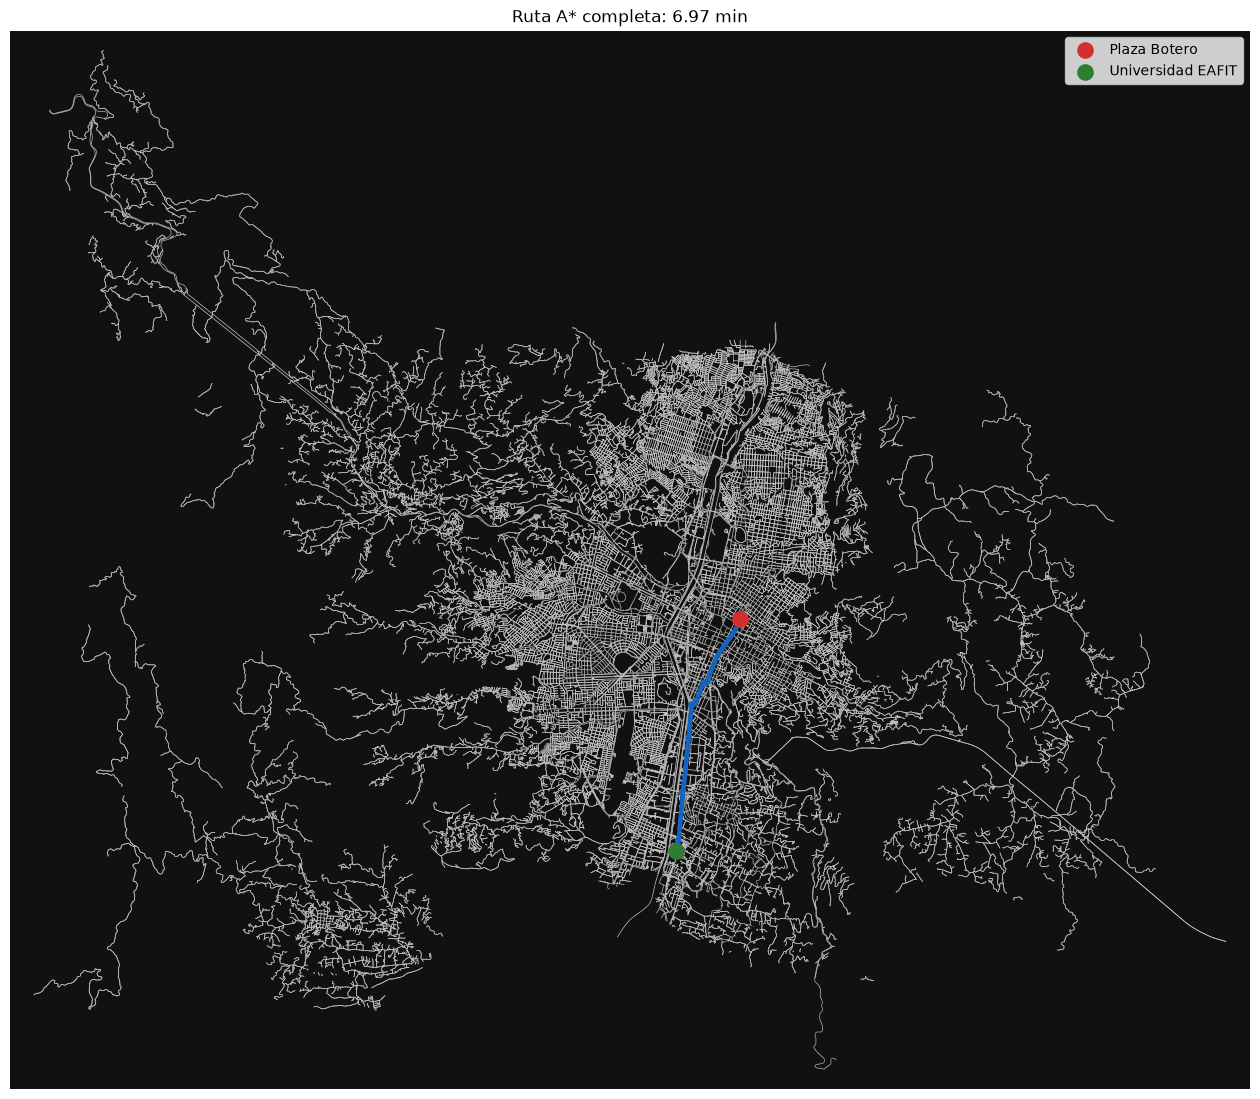

RESULTADO_REAL real_edge ACCIDENTES 235820 ASOCIADOS 57002 SEGMENTOS 7718 COMBINACIONES 33989
RIESGO (0.023809523809523808, 1.0)
A_STAR True 416.7 aristas 205
A_STAR_BALANCED True 417.95 penalizacion 1.25 aristas 205


In [21]:
start_place = selected_place("Plaza Botero")
end_place = selected_place("EAFIT")
start_id, _ = nearest_valid_node(start_place)
end_id, _ = nearest_valid_node(end_place)
OSMRouteNode.configure(G, perfiles_costo["1. Solo travel_time"], ACCIDENT_RISK, 17, beta=0.0)
fast_tree = OSMRouteTree(OSMRouteNode(state=(None, start_id, None), value="runall-fast", objective=end_id, accumulated_cost=0.0))
fast_result = result_from_goal(fast_tree.aStar(end_id), fast_tree)
validate_composite_route(fast_result, start_id, end_id)
OSMRouteNode.configure(G, perfiles_costo["5. Balanced histórico"], ACCIDENT_RISK, 17, beta=0.5)
balanced_tree = OSMRouteTree(OSMRouteNode(state=(None, start_id, None), value="runall-balanced", objective=end_id, accumulated_cost=0.0))
balanced_result = result_from_goal(balanced_tree.aStar(end_id), balanced_tree)
validate_composite_route(balanced_result, start_id, end_id)
fast_gdf = build_route_geodata(fast_result)
balanced_gdf = build_route_geodata(balanced_result)
plot_static_route(balanced_result, start_place, end_place)
comparison_figure = make_comparison_map(fast_gdf, balanced_gdf, start_place, end_place)
animation_figure = make_route_animation(balanced_gdf, start_place, end_place, MAPBOX_TOKEN)
display(comparison_figure)
display(animation_figure)
print("RESULTADO_REAL", DATA_MODE, "ACCIDENTES", len(INCIDENTS), "ASOCIADOS", ACCIDENT_EDGE_ASSOCIATION_STATS["associated"], "SEGMENTOS", len(ACCIDENT_COUNTS_NESTED), "COMBINACIONES", len(ACCIDENT_COUNTS))
print("RIESGO", (min(ACCIDENT_RISK.values()), max(ACCIDENT_RISK.values())) if ACCIDENT_RISK else (0,0))
print("A_STAR", fast_result["found"], round(fast_result["total_cost_s"],2), "aristas", len(fast_result["route_edges"]))
print("A_STAR_BALANCED", balanced_result["found"], round(balanced_result["total_cost_s"],2), "penalizacion", round(sum(d["historical_penalty_s"] for d in balanced_result["edge_details"]),2), "aristas", len(balanced_result["route_edges"]))


# Demostración: cómo Waze IA evita zonas de alta accidentalidad

Esta sección busca en el grafo y las asociaciones reales un caso donde la ruta de menor tiempo atraviese segmentos de alta accidentalidad histórica y A* Balanced reduzca esa exposición. La clasificación de “alta accidentalidad” se fija en riesgo normalizado por hora **≥ 0,5**; este valor es frecuencia relativa histórica, no probabilidad.

La búsqueda prueba todas las parejas dirigidas de los lugares estandarizados, las horas 07:00, 08:00, 17:00 y 18:00, y beta 0,5, 1, 2 y 5. Ambos algoritmos usan el mismo grafo, perfil y hora; solo cambia beta. Si no hay un caso que cumpla los criterios, la sección lo informa sin fabricar una demostración.

In [22]:
from itertools import combinations
import math

DEMO_HOURS = (7, 8, 17, 18)
DEMO_BETAS = (0.5, 1.0, 2.0, 5.0)
DEMO_HIGH_RISK_THRESHOLD = 0.5
DEMO_SEARCH_LOG = []
DEMO_CASE = None

# Unir IDs desde la tabla individual: cada accidente cuenta una sola vez,
# aunque una métrica futura recorra una arista repetida.
DEMO_INCIDENT_IDS_BY_EDGE_HOUR = {}
for row in INCIDENT_EDGE_ASSOCIATIONS.itertuples(index=False):
    edge_hour = (row.u, row.v, row.key, int(row.hour))
    DEMO_INCIDENT_IDS_BY_EDGE_HOUR.setdefault(edge_hour, set()).add(row.accident_id)

DEMO_CONFIG = perfiles_costo["5. Balanced histórico"]

def _demo_route_metrics(result, hour):
    edges = list(dict.fromkeys(result["route_edges"]))
    base_time = 0.0
    penalty = 0.0
    high_edges = set()
    edges_with_incidents = 0
    incident_ids = set()
    for u, v, key in edges:
        data = G.edges[u, v, key]
        times = OSMRouteNode._as_numbers(data.get("travel_time"))
        if not times:
            raise ValueError(f"La arista {(u,v,key)} no tiene travel_time.")
        seconds = float(times[0])
        risk = edge_risk(ACCIDENT_RISK, u, v, key, hour)
        ids = DEMO_INCIDENT_IDS_BY_EDGE_HOUR.get((u, v, key, int(hour)), set())
        base_time += seconds
        if risk >= DEMO_HIGH_RISK_THRESHOLD:
            high_edges.add((u, v, key))
        if ids:
            edges_with_incidents += 1
            incident_ids.update(ids)
    # Derive the historical penalty directly from the same beta and hourly risk
    # used by transition_cost, then verify it against A*'s reported path cost.
    beta = float(result.get("beta", 0.0))
    penalty = sum(
        float(OSMRouteNode._as_numbers(G.edges[u, v, key].get("travel_time"))[0])
        * beta * edge_risk(ACCIDENT_RISK, u, v, key, hour)
        for u, v, key in edges
    )
    return {
        "edges": edges,
        "base_time_s": base_time,
        "historical_penalty_s": penalty,
        "total_cost_s": float(result["total_cost_s"]),
        "edge_count": len(edges),
        "edges_with_incidents": edges_with_incidents,
        "incident_ids": incident_ids,
        "accident_count": len(incident_ids),
        "high_edges": high_edges,
        "risk_by_edge": {
            edge: edge_risk(ACCIDENT_RISK, *edge, hour) for edge in edges
        },
    }

def _demo_search(start_id, end_id, hour, beta):
    OSMRouteNode.configure(G, DEMO_CONFIG, ACCIDENT_RISK, hour, beta=beta)
    tree = OSMRouteTree(OSMRouteNode(
        state=(None, start_id, None), value="demo", objective=end_id,
        accumulated_cost=0.0,
    ))
    result = result_from_goal(tree.aStar(end_id), tree)
    if result["found"]:
        validate_composite_route(result, start_id, end_id)
    result["beta"] = float(beta)
    return result

# Baselines once per directed pair. A* beta=0 is independent of hour.
place_keys = list(LUGARES_VALIDOS)
ordered_pairs = list(combinations(place_keys, 2))
priority_pairs = [
    ("Plaza Botero", "EAFIT"), ("Terminal Norte", "Estadio"),
    ("Parque Poblado", "Hospital General"), ("Estadio", "Parque Arvi"),
    ("EAFIT", "Terminal Norte"),
]
directed_pairs = []
for pair in priority_pairs:
    for direction in (pair, pair[::-1]):
        if direction not in directed_pairs:
            directed_pairs.append(direction)
for a, b in ordered_pairs:
    for direction in ((a, b), (b, a)):
        if direction not in directed_pairs:
            directed_pairs.append(direction)

fast_by_pair = {}
candidates = []
for origin, destination in directed_pairs:
    try:
        start_id, _ = nearest_valid_node(selected_place(origin))
        end_id, _ = nearest_valid_node(selected_place(destination))
        fast = _demo_search(start_id, end_id, DEMO_HOURS[0], 0.0)
    except (ValueError, AssertionError) as error:
        DEMO_SEARCH_LOG.append({"origen": origin, "destino": destination, "estado": f"omitido: {error}"})
        continue
    if not fast["found"]:
        DEMO_SEARCH_LOG.append({"origen": origin, "destino": destination, "estado": "sin ruta dirigida"})
        continue
    fast_by_pair[(origin, destination)] = (start_id, end_id, fast)
    for hour in DEMO_HOURS:
        fast_metrics = _demo_route_metrics(fast, hour)
        high_accidents = set().union(*(
            DEMO_INCIDENT_IDS_BY_EDGE_HOUR.get((*edge, hour), set())
            for edge in fast_metrics["high_edges"]
        )) if fast_metrics["high_edges"] else set()
        if not fast_metrics["high_edges"] or not high_accidents:
            continue
        candidates.append({
            "origin": origin, "destination": destination,
            "start_id": start_id, "end_id": end_id, "fast": fast,
            "hour": hour, "fast_metrics": fast_metrics,
            "score": (len(fast_metrics["high_edges"]), len(high_accidents),
                      sum(fast_metrics["risk_by_edge"].values())),
        })

# Try the strongest real fast-route exposures first, then every beta in the
# requested order; stop at the first case meeting all explicit criteria.
candidates.sort(key=lambda x: (-x["score"][0], -x["score"][1], -x["score"][2],
                               DEMO_HOURS.index(x["hour"]), x["origin"], x["destination"]))
for candidate in candidates:
    origin, destination, hour = candidate["origin"], candidate["destination"], candidate["hour"]
    fast = candidate["fast"]
    fm = candidate["fast_metrics"]
    for beta in DEMO_BETAS:
        balanced = _demo_search(candidate["start_id"], candidate["end_id"], hour, beta)
        if not balanced["found"] or balanced["route_nodes"][-1] != candidate["end_id"]:
            DEMO_SEARCH_LOG.append({"origen": origin, "destino": destination, "hora": hour,
                                    "beta": beta, "estado": "Balanced sin destino común"})
            continue
        bm = _demo_route_metrics(balanced, hour)
        balanced_edges = set(bm["edges"])
        avoided = sorted(fm["high_edges"] - balanced_edges)
        high_reduction = ((len(fm["high_edges"]) - len(bm["high_edges"])) / len(fm["high_edges"]))
        cost_expected = bm["base_time_s"] + bm["historical_penalty_s"]
        if not math.isclose(cost_expected, balanced["total_cost_s"], rel_tol=1e-9, abs_tol=1e-6):
            raise AssertionError("Coste calculado no coincide con el total de A* Balanced.")
        row = {
            "origen": origin, "destino": destination, "hora": hour,
            "beta": beta, "segmentos_alto_riesgo_fast": len(fm["high_edges"]),
            "segmentos_alto_riesgo_balanced": len(bm["high_edges"]),
            "segmentos_alto_riesgo_evitados": len(avoided),
            "reduccion_alto_riesgo_pct": round(100*high_reduction, 1),
            "accidentes_fast": fm["accident_count"],
            "accidentes_balanced": bm["accident_count"],
            "aristas_fast": fm["edge_count"], "aristas_balanced": bm["edge_count"],
            "estado": "ruta igual" if tuple(fast["route_edges"]) == tuple(balanced["route_edges"]) else "ruta distinta",
        }
        DEMO_SEARCH_LOG.append(row)
        qualifies = (
            tuple(fast["route_edges"]) != tuple(balanced["route_edges"])
            and len(avoided) >= 1
            and high_reduction >= 0.5
            and fm["accident_count"] > bm["accident_count"]
        )
        if qualifies:
            DEMO_CASE = {
                **candidate, "balanced": balanced, "balanced_metrics": bm,
                "avoided_edges": avoided,
                "accidents_reduction_pct": 100*(fm["accident_count"]-bm["accident_count"])/fm["accident_count"],
                "route_changed": True,
            }
            break
    if DEMO_CASE is not None:
        break

# Si las ubicaciones estandarizadas no muestran hotspots en sus rutas rápidas,
# usar pares reales de nodos al extremo de aristas con conteos históricos altos.
# Las coordenadas proceden del propio grafo; no se geocodifican ni inventan.
if DEMO_CASE is None:
    targets_by_pair_hour = {}
    for (u, v, key, hour), risk in ACCIDENT_RISK.items():
        if hour not in DEMO_HOURS or risk < DEMO_HIGH_RISK_THRESHOLD:
            continue
        ids = DEMO_INCIDENT_IDS_BY_EDGE_HOUR.get((u, v, key, int(hour)), set())
        if not ids:
            continue
        targets_by_pair_hour.setdefault((u, v, int(hour)), []).append(
            (float(risk), len(ids), key)
        )
    edge_targets = sorted(
        targets_by_pair_hour.items(),
        key=lambda item: (-max(x[1] for x in item[1]),
                          -max(x[0] for x in item[1]),
                          -sum(x[1] for x in item[1]),
                          int(item[0][0]), int(item[0][1]), item[0][2]),
    )
    print("Segmentos dirigidos con R ≥ 0,5 en horas objetivo:", len(edge_targets))
    fast_endpoint_cache = {}

    def _osm_node_label(node_id):
        names = set()
        for _, _, _, data in G.in_edges(node_id, keys=True, data=True):
            value = data.get("name")
            names.update(str(x) for x in OSMRouteNode._as_osm_values(value) if x)
        for _, _, _, data in G.out_edges(node_id, keys=True, data=True):
            value = data.get("name")
            names.update(str(x) for x in OSMRouteNode._as_osm_values(value) if x)
        suffix = f" · {', '.join(sorted(names)[:2])}" if names else ""
        return f"Nodo vial OSM {node_id}{suffix}"

    for (u, v, hour), target_values in edge_targets:
        pair = (u, v)
        if pair not in fast_endpoint_cache:
            fast_endpoint_cache[pair] = _demo_search(u, v, DEMO_HOURS[0], 0.0)
        fast = fast_endpoint_cache[pair]
        if not fast["found"]:
            continue
        fm = _demo_route_metrics(fast, hour)
        if not fm["high_edges"]:
            continue
        fast_high_ids = set().union(*(
            DEMO_INCIDENT_IDS_BY_EDGE_HOUR.get((*edge, hour), set())
            for edge in fm["high_edges"]
        ))
        if not fast_high_ids:
            continue
        for beta in DEMO_BETAS:
            balanced = _demo_search(u, v, hour, beta)
            bm = _demo_route_metrics(balanced, hour) if balanced["found"] else None
            avoided = sorted(fm["high_edges"] - set(bm["edges"])) if bm else []
            reduction = ((len(fm["high_edges"])-len(bm["high_edges"]))/len(fm["high_edges"])) if bm else 0.0
            log_row = {
                "origen_nodo": u, "destino_nodo": v, "hora": hour, "beta": beta,
                "alto_riesgo_fast": len(fm["high_edges"]),
                "alto_riesgo_balanced": len(bm["high_edges"]) if bm else None,
                "evitados": len(avoided), "reduccion_alto_riesgo_pct": round(100*reduction,1),
                "accidentes_fast": fm["accident_count"],
                "accidentes_balanced": bm["accident_count"] if bm else None,
                "estado": "sin ruta" if not bm else ("igual" if tuple(fast["route_edges"]) == tuple(balanced["route_edges"]) else "distinta"),
            }
            DEMO_SEARCH_LOG.append(log_row)
            qualifies = (
                bm is not None
                and tuple(fast["route_edges"]) != tuple(balanced["route_edges"])
                and len(avoided) >= 1
                and reduction >= 0.5
                and fm["accident_count"] > bm["accident_count"]
                and balanced["route_nodes"][-1] == v
            )
            if qualifies:
                origin_place = {"nombre": _osm_node_label(u), "lat": float(G.nodes[u]["y"]), "lon": float(G.nodes[u]["x"])}
                destination_place = {"nombre": _osm_node_label(v), "lat": float(G.nodes[v]["y"]), "lon": float(G.nodes[v]["x"])}
                DEMO_CASE = {
                    "origin": origin_place["nombre"], "destination": destination_place["nombre"],
                    "origin_place": origin_place, "destination_place": destination_place,
                    "start_id": u, "end_id": v, "hour": hour, "fast": fast,
                    "fast_metrics": fm, "balanced": balanced, "balanced_metrics": bm,
                    "avoided_edges": avoided, "route_changed": True,
                    "accidents_reduction_pct": 100*(fm["accident_count"]-bm["accident_count"])/fm["accident_count"],
                    "origin_type": "nodo real del grafo OSM; coordenadas del grafo local",
                }
                break
        if DEMO_CASE is not None:
            break

print(f"Parejas dirigidas evaluadas con ruta base: {len(fast_by_pair)} de {len(directed_pairs)}")
print(f"Combinaciones hora con segmentos de alto riesgo: {len(candidates)}")
print(f"Comparaciones Balanced ejecutadas: {sum('estado' in row and 'beta' in row for row in DEMO_SEARCH_LOG)}")
if DEMO_CASE is None:
    print("NO SE ENCONTRÓ un caso que cumpla todos los criterios; no se fabricó ni relajó el resultado.")
else:
    c = DEMO_CASE
    print("CASO REAL", c["origin"], "→", c["destination"], f"{c['hour']:02d}:00", "beta", c["balanced"]["beta"])
    print("Origen/destino:", c["origin_type"] if "origin_type" in c else "lugares estandarizados")
    print("Segmentos de alto riesgo evitados:", len(c["avoided_edges"]))
    print("Accidentes históricos únicos:", c["fast_metrics"]["accident_count"], "→", c["balanced_metrics"]["accident_count"])
    display(pd.DataFrame(DEMO_SEARCH_LOG).tail(20))


Segmentos dirigidos con R ≥ 0,5 en horas objetivo: 18


Parejas dirigidas evaluadas con ruta base: 42 de 42
Combinaciones hora con segmentos de alto riesgo: 0
Comparaciones Balanced ejecutadas: 40
CASO REAL Nodo vial OSM 1814542378 · Avenida del Ferrocarril, Calle 39 → Nodo vial OSM 339054018 · Avenida del Ferrocarril, Calle 40A 18:00 beta 5.0
Origen/destino: nodo real del grafo OSM; coordenadas del grafo local
Segmentos de alto riesgo evitados: 1
Accidentes históricos únicos: 26 → 2


,origen_nodo,destino_nodo,hora,beta,alto_riesgo_fast,alto_riesgo_balanced,evitados,reduccion_alto_riesgo_pct,accidentes_fast,accidentes_balanced,estado
20,9415958710,9415958709,7,0.5,1,1,0,0.0,34,34,igual
21,9415958710,9415958709,7,1.0,1,1,0,0.0,34,34,igual
22,9415958710,9415958709,7,2.0,1,1,0,0.0,34,34,igual
23,9415958710,9415958709,7,5.0,1,1,0,0.0,34,34,igual
24,4449274609,9370054340,8,0.5,1,1,0,0.0,33,33,igual
25,4449274609,9370054340,8,1.0,1,1,0,0.0,33,33,igual
26,4449274609,9370054340,8,2.0,1,1,0,0.0,33,33,igual
27,4449274609,9370054340,8,5.0,1,1,0,0.0,33,33,igual
28,9415958710,9415958709,18,0.5,1,1,0,0.0,30,30,igual
29,9415958710,9415958709,18,1.0,1,1,0,0.0,30,30,igual


## Métricas de las dos rutas

In [23]:
if DEMO_CASE is None:
    display(HTML("<b>No hay un caso válido que visualizar.</b> Revisa la tabla de combinaciones probadas en la celda anterior; no se alteraron datos ni costes."))
else:
    c = DEMO_CASE; fm = c["fast_metrics"]; bm = c["balanced_metrics"]
    DEMO_AVOIDED_ROWS = []
    for u, v, key in c["avoided_edges"]:
        ids = DEMO_INCIDENT_IDS_BY_EDGE_HOUR.get((u, v, key, int(c["hour"])), set())
        edge_data = G.edges[u, v, key]
        DEMO_AVOIDED_ROWS.append({
            "u": u, "v": v, "key": key,
            "vía": ", ".join(map(str, OSMRouteNode._as_osm_values(edge_data.get("highway")))),
            "riesgo normalizado": edge_risk(ACCIDENT_RISK, u, v, key, c["hour"]),
            "accidentes históricos únicos en esa hora": len(ids),
            "distancia arista (m)": float(edge_data.get("length", 0.0)),
        })
    DEMO_METRICS = pd.DataFrame([
        {"Métrica": "Tiempo base (s)", "A* tradicional": fm["base_time_s"], "A* Balanced": bm["base_time_s"]},
        {"Métrica": "Penalización histórica (s)", "A* tradicional": fm["historical_penalty_s"], "A* Balanced": bm["historical_penalty_s"]},
        {"Métrica": "Coste total A* (s)", "A* tradicional": c["fast"]["total_cost_s"], "A* Balanced": c["balanced"]["total_cost_s"]},
        {"Métrica": "Aristas recorridas", "A* tradicional": fm["edge_count"], "A* Balanced": bm["edge_count"]},
        {"Métrica": "Aristas con accidentes a esa hora", "A* tradicional": fm["edges_with_incidents"], "A* Balanced": bm["edges_with_incidents"]},
        {"Métrica": "Accidentes históricos únicos a esa hora", "A* tradicional": fm["accident_count"], "A* Balanced": bm["accident_count"]},
        {"Métrica": "Segmentos alto riesgo (R ≥ 0,5)", "A* tradicional": len(fm["high_edges"]), "A* Balanced": len(bm["high_edges"])},
        {"Métrica": "Hora", "A* tradicional": f"{c['hour']:02d}:00", "A* Balanced": f"{c['hour']:02d}:00"},
        {"Métrica": "Beta", "A* tradicional": 0.0, "A* Balanced": c["balanced"]["beta"]},
    ])
    display(DEMO_METRICS.round(3))
    print("Segmentos de alto riesgo que la ruta tradicional atraviesa y Balanced evita:")
    display(pd.DataFrame(DEMO_AVOIDED_ROWS).round(3))


,Métrica,A* tradicional,A* Balanced
0,Tiempo base (s),9.260892,25.158759
1,Penalización histórica (s),0.0,2.326058
2,Coste total A* (s),9.260892,27.484817
3,Aristas recorridas,1,8
4,Aristas con accidentes a esa hora,1,1
5,Accidentes históricos únicos a esa hora,26,2
6,"Segmentos alto riesgo (R ≥ 0,5)",1,0
7,Hora,18:00,18:00
8,Beta,0.0,5.0


Segmentos de alto riesgo que la ruta tradicional atraviesa y Balanced evita:


,u,v,key,vía,riesgo normalizado,accidentes históricos únicos en esa hora,distancia arista (m)
0,1814542378,339054018,0,secondary,0.619,26,128.624


## Visualización 1. Mapa comparativo de rutas

In [24]:
if DEMO_CASE is None:
    display(HTML("Mapa omitido: no se encontró un caso demostrativo válido."))
else:
    c = DEMO_CASE; hour = int(c["hour"])
    def _demo_line_coords(edges):
        lon, lat = [], []
        for edge in edges:
            geom = geometry_of_edge(*edge)
            parts = list(geom.geoms) if hasattr(geom, "geoms") else [geom]
            for part in parts:
                xy = list(part.coords)
                lon.extend([point[0] for point in xy] + [None])
                lat.extend([point[1] for point in xy] + [None])
        return lon, lat
    fast_lon, fast_lat = _demo_line_coords(c["fast_metrics"]["edges"])
    balanced_lon, balanced_lat = _demo_line_coords(c["balanced_metrics"]["edges"])
    avoid_lon, avoid_lat = _demo_line_coords(c["avoided_edges"])
    balanced_high = sorted(c["balanced_metrics"]["high_edges"])
    bh_lon, bh_lat = _demo_line_coords(balanced_high)
    start = c["origin_place"] if "origin_place" in c else selected_place(c["origin"]); end = c["destination_place"] if "destination_place" in c else selected_place(c["destination"])
    center = {"lat": (start["lat"]+end["lat"])/2, "lon": (start["lon"]+end["lon"])/2}
    figure = go.Figure([
        go.Scattermap(lon=fast_lon, lat=fast_lat, mode="lines", name="A* tradicional",
                      line={"width": 5, "color": "#1565C0"}),
        go.Scattermap(lon=balanced_lon, lat=balanced_lat, mode="lines", name="A* Balanced",
                      line={"width": 5, "color": "#F57C00"}),
        go.Scattermap(lon=avoid_lon, lat=avoid_lat, mode="lines", name="Alto riesgo: tradicional lo usa y Balanced lo evita",
                      line={"width": 9, "color": "#D32F2F"}),
        go.Scattermap(lon=bh_lon, lat=bh_lat, mode="lines", name="Alto riesgo aún presente en Balanced",
                      line={"width": 8, "color": "#FDD835"}),
        go.Scattermap(lon=[start["lon"]], lat=[start["lat"]], mode="markers", name=f"Origen: {c['origin']}",
                      marker={"size": 14, "color": "#2E7D32"}),
        go.Scattermap(lon=[end["lon"]], lat=[end["lat"]], mode="markers", name=f"Destino: {c['destination']}",
                      marker={"size": 14, "color": "#6A1B9A"}),
    ])
    figure.update_layout(
        map={"style": "carto-positron", "center": center, "zoom": 14},
        title=f"Rutas reales en Medellín · {hour:02d}:00 · beta {c['balanced']['beta']:g}",
        height=700, legend={"title": "Activa/desactiva capas desde la leyenda"},
    )
    display(figure)


## Visualización 2. Accidentes históricos asociados a cada ruta

In [25]:
if DEMO_CASE is None:
    display(HTML("Gráfico omitido: no hay un caso demostrativo válido."))
else:
    c = DEMO_CASE; fm = c["fast_metrics"]; bm = c["balanced_metrics"]
    figure = go.Figure(go.Bar(
        x=["A* tradicional", "A* Balanced"],
        y=[fm["accident_count"], bm["accident_count"]],
        marker_color=["#1565C0", "#F57C00"],
        text=[fm["accident_count"], bm["accident_count"]], textposition="outside",
        hovertemplate="%{x}<br>Accidentes históricos únicos: %{y}<extra></extra>",
    ))
    figure.update_layout(title=f"Incidentes asociados a los segmentos recorridos · {c['hour']:02d}:00",
                         yaxis_title="IDs de accidente únicos", height=430)
    display(figure)
    print("Cálculo: unión de accident_id en INCIDENT_EDGE_ASSOCIATIONS para las aristas distintas de cada ruta y la hora elegida. Cada registro aparece una sola vez en la tabla de asociación, y la unión impide doble conteo.")


Cálculo: unión de accident_id en INCIDENT_EDGE_ASSOCIATIONS para las aristas distintas de cada ruta y la hora elegida. Cada registro aparece una sola vez en la tabla de asociación, y la unión impide doble conteo.


## Visualización 3. Descomposición de costes

In [26]:
if DEMO_CASE is None:
    display(HTML("Gráfico omitido: no hay un caso demostrativo válido."))
else:
    c = DEMO_CASE; fm = c["fast_metrics"]; bm = c["balanced_metrics"]
    routes = ["A* tradicional", "A* Balanced"]
    base = [fm["base_time_s"], bm["base_time_s"]]
    penalty = [fm["historical_penalty_s"], bm["historical_penalty_s"]]
    total = [c["fast"]["total_cost_s"], c["balanced"]["total_cost_s"]]
    figure = go.Figure([
        go.Bar(name="Tiempo base", x=routes, y=base, marker_color="#1565C0"),
        go.Bar(name="Penalización histórica", x=routes, y=penalty, marker_color="#F57C00"),
        go.Scatter(name="Coste total A*", x=routes, y=total, mode="markers+text",
                   marker={"size": 13, "color": "#212121"}, text=[f"{v:.1f} s" for v in total],
                   textposition="top center"),
    ])
    figure.update_layout(barmode="stack", title="Tiempo base + penalización histórica; punto = coste total",
                         yaxis_title="Segundos", height=470)
    display(figure)


## Visualización 4. Perfil horario de riesgo por segmento

In [27]:
if DEMO_CASE is None:
    display(HTML("Perfil omitido: no hay un caso demostrativo válido."))
else:
    c = DEMO_CASE; hour = int(c["hour"])
    fast_edges = c["fast_metrics"]["edges"]
    balanced_edges = c["balanced_metrics"]["edges"]
    fast_risk = [edge_risk(ACCIDENT_RISK, *edge, hour) for edge in fast_edges]
    balanced_risk = [edge_risk(ACCIDENT_RISK, *edge, hour) for edge in balanced_edges]
    figure = go.Figure([
        go.Scatter(x=list(range(1,len(fast_risk)+1)), y=fast_risk, mode="lines+markers",
                   name="A* tradicional", line={"color":"#1565C0"},
                   marker={"color":["#D32F2F" if v>=DEMO_HIGH_RISK_THRESHOLD else "#1565C0" for v in fast_risk]}),
        go.Scatter(x=list(range(1,len(balanced_risk)+1)), y=balanced_risk, mode="lines+markers",
                   name="A* Balanced", line={"color":"#F57C00"},
                   marker={"color":["#D32F2F" if v>=DEMO_HIGH_RISK_THRESHOLD else "#F57C00" for v in balanced_risk]}),
    ])
    figure.add_hline(y=DEMO_HIGH_RISK_THRESHOLD, line_dash="dash", line_color="#D32F2F",
                     annotation_text="Umbral de alto riesgo (R = 0,5)")
    figure.update_layout(title=f"Riesgo normalizado de cada segmento recorrido · {hour:02d}:00",
                         xaxis_title="Orden del segmento en la ruta", yaxis_title="Riesgo normalizado (0–1)",
                         yaxis={"range":[0,1]}, height=500)
    display(figure)


## Indicadores y explicación del caso

In [28]:
if DEMO_CASE is None:
    display(HTML("No se puede emitir un resumen de un caso no encontrado. Consulta la tabla de combinaciones probadas."))
else:
    c=DEMO_CASE; fm=c["fast_metrics"]; bm=c["balanced_metrics"]
    time_difference = bm["base_time_s"] - fm["base_time_s"]
    accident_difference = fm["accident_count"] - bm["accident_count"]
    reduction_pct = (100*accident_difference/fm["accident_count"]
                     if fm["accident_count"] > 0 else None)
    indicators = pd.DataFrame([
        {"Indicador":"Tiempo estimado A* tradicional (s)","Resultado":round(fm["base_time_s"],2)},
        {"Indicador":"Tiempo estimado A* Balanced (s)","Resultado":round(bm["base_time_s"],2)},
        {"Indicador":"Diferencia de tiempo base (s)","Resultado":round(time_difference,2)},
        {"Indicador":"Coste total tradicional (s)","Resultado":round(c["fast"]["total_cost_s"],2)},
        {"Indicador":"Coste total Balanced (s)","Resultado":round(c["balanced"]["total_cost_s"],2)},
        {"Indicador":"Segmentos alto riesgo evitados","Resultado":len(c["avoided_edges"])},
        {"Indicador":"Accidentes históricos únicos: tradicional","Resultado":fm["accident_count"]},
        {"Indicador":"Accidentes históricos únicos: Balanced","Resultado":bm["accident_count"]},
        {"Indicador":"Diferencia de accidentes históricos únicos","Resultado":accident_difference},
        {"Indicador":"Reducción relativa de la métrica (%)","Resultado":round(reduction_pct,2) if reduction_pct is not None else "N/A"},
        {"Indicador":"Hora","Resultado":f"{c['hour']:02d}:00"},
        {"Indicador":"Beta","Resultado":c["balanced"]["beta"]},
    ])
    display(indicators)
    reduction_text = (f"una reducción de {reduction_pct:.1f}% en la métrica de accidentes históricos únicos asociados a los segmentos recorridos"
                      if reduction_pct is not None else "sin porcentaje de reducción porque la base de accidentes es cero")
    print(
        f"Entre {c['origin']} y {c['destination']}, a las {c['hour']:02d}:00, A* tradicional seleccionó una ruta que atravesaba "
        f"{len(fm['high_edges'])} segmentos con alta accidentalidad histórica (R ≥ {DEMO_HIGH_RISK_THRESHOLD:.1f}). "
        f"A* Balanced, con beta {c['balanced']['beta']:g}, encontró una ruta alternativa que evitó "
        f"{len(c['avoided_edges'])} de esos segmentos. El tiempo base cambió en "
        f"{time_difference:.1f} s y hubo {accident_difference} accidentes históricos únicos menos asociados "
        f"a sus segmentos; {reduction_text}. Estos conteos históricos no son probabilidades ni predicciones futuras."
    )


,Indicador,Resultado
0,Tiempo estimado A* tradicional (s),9.26
1,Tiempo estimado A* Balanced (s),25.16
2,Diferencia de tiempo base (s),15.9
3,Coste total tradicional (s),9.26
4,Coste total Balanced (s),27.48
5,Segmentos alto riesgo evitados,1
6,Accidentes históricos únicos: tradicional,26
7,Accidentes históricos únicos: Balanced,2
8,Diferencia de accidentes históricos únicos,24
9,Reducción relativa de la métrica (%),92.31


Entre Nodo vial OSM 1814542378 · Avenida del Ferrocarril, Calle 39 y Nodo vial OSM 339054018 · Avenida del Ferrocarril, Calle 40A, a las 18:00, A* tradicional seleccionó una ruta que atravesaba 1 segmentos con alta accidentalidad histórica (R ≥ 0.5). A* Balanced, con beta 5, encontró una ruta alternativa que evitó 1 de esos segmentos. El tiempo base cambió en 15.9 s y hubo 24 accidentes históricos únicos menos asociados a sus segmentos; una reducción de 92.3% en la métrica de accidentes históricos únicos asociados a los segmentos recorridos. Estos conteos históricos no son probabilidades ni predicciones futuras.


# Demostración final: así A* Balanced evita el tramo de alta accidentalidad

Los resultados de todo el notebook están guardados en este archivo. Al abrirlo en Colab, desplázate hasta esta sección para ver el mapa ya generado. El mapa usa salida HTML de Plotly compatible con Colab: azul = A* tradicional, naranja = A* Balanced y rojo = tramo de alto riesgo que la ruta tradicional recorre y Balanced evita. Puedes activar o desactivar cada capa desde la leyenda. Los indicadores del caso se calculan con los datos reales cargados arriba.

# Documentación técnica: heurística A* y accidentalidad histórica

## Qué estima la heurística

En `OSMRouteNode.heuristic()`, la heurística `h(n)` estima los segundos que faltan desde el nodo actual hasta el destino. Calcula la distancia geodésica en línea recta con Haversine y la divide por la velocidad máxima observada en el grafo:

$$h(n)=\frac{d_{\text{Haversine}}(n, destino)\cdot 3.6}{v_{\max}}$$

La misma función se utiliza para A* tradicional y A* Balanced. Es una estimación optimista del tiempo restante: la ruta vial real no puede ser más corta que la línea recta y la velocidad usada es un límite superior. **Esta heurística no conoce los accidentes ni cambia de ruta por sí sola.**

## Dónde entra la accidentalidad

A* ordena sus estados con $f(n)=g(n)+h(n)$. `g(n)` es el coste acumulado de las aristas recorridas: tiempo base, ajuste por tipo de vía, demora de intersección y giro. Cuando `DATA_MODE="real_edge"`, `transition_cost()` consulta el riesgo normalizado de la arista dirigida `(u, v, key)` para la hora seleccionada y suma:

$$P_{histórica}(e,h)=t_{base}(e)\cdot\beta\cdot R(e,h)$$

Por tanto, en Balanced cada tramo con más riesgo histórico eleva el coste acumulado. Si una alternativa de menor riesgo cuesta menos que la penalización que evita, A* termina eligiéndola. `beta` controla cuánto pesa ese término: con `beta=0` no hay penalización histórica y se obtiene la búsqueda tradicional; un `beta` mayor hace más caro atravesar segmentos con riesgo alto. La hora se mantiene fija en las dos búsquedas y determina qué perfil horario de riesgo se consulta.

Los riesgos se normalizan por hora entre 0 y 1 usando los conteos históricos reales. El conteo asociado a una arista identifica registros de accidentalidad observados; no es una probabilidad de accidente futuro.

## Lectura del caso que aparece arriba

En la comparación reproducida para las 18:00, con `beta=5`, A* tradicional eligió el tramo dirigido de riesgo normalizado `0,619`. Balanced lo evitó y tomó una ruta alternativa. La métrica histórica de incidentes únicos asociados a las aristas recorridas pasó de 26 a 2 (reducción de 92,3% para este caso). En las combinaciones probadas para este origen/destino y hora, `beta=0,5`, `1` y `2` conservaron la ruta tradicional; `beta=5` produjo el desvío.

El tiempo base estimado cambió de 9,26 s a 25,16 s: **15,90 s más en términos absolutos**. Como el trayecto original es muy corto, eso equivale aproximadamente a un aumento del 172% respecto de su tiempo base; no sería correcto describirlo como un aumento pequeño en términos relativos. Balanced acumuló además 2,33 s de penalización histórica dentro de su función objetivo. Esa penalización es un peso de optimización para comparar rutas, no tiempo físico añadido al reloj de llegada.

El caso muestra el mecanismo y su intercambio: A* prefiere la alternativa cuando el coste de la ruta de menor riesgo compensa la penalización del segmento peligroso. No garantiza que se eviten accidentes reales ni que el desvío siempre sea breve. Para priorizar más el tiempo se puede reducir `beta`; para obtener una decisión distinta con una demora menor hay que evaluar otros pares de origen/destino, horas y valores de `beta` con el mismo grafo y medir de nuevo ambos tiempos. No se debe presentar la reducción histórica como predicción de accidentes futuros.

# Ruta larga interactiva: cambio de recorrido al aumentar beta

El control inferior permite aumentar `beta` y ver cuándo cambia la ruta, usando el grafo y los conteos históricos reales. **Naranja:** ruta para el beta seleccionado. **Rojo:** segmento de alto riesgo de la ruta rápida que se evita. El mapa queda guardado ya ejecutado para verlo al abrir en Colab.

In [29]:
# Búsqueda acotada de una ruta de varios kilómetros que atraviese un segmento real de alto riesgo.
# Se extiende desde los extremos del hotspot real encontrado arriba hacia destinos lejanos
# del grafo y se valida cada alternativa con la implementación A* del proyecto.
if DEMO_CASE is None:
    display(HTML("No hay un hotspot real válido para construir esta demostración."))
else:
    from math import radians, sin, cos, asin, sqrt
    import plotly.graph_objects as go
    import plotly.io as pio

    LONG_ROUTE_MIN_M = 3500.0
    ROUTE_HOUR = int(DEMO_CASE["hour"])
    BETA_STEPS = (0.0, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0)
    hotspot_u = DEMO_CASE["start_id"]
    hotspot_v = DEMO_CASE["end_id"]

    def _great_circle_m(a, b):
        lat1, lon1 = radians(a["lat"]), radians(a["lon"])
        lat2, lon2 = radians(b["lat"]), radians(b["lon"])
        dlat, dlon = lat2-lat1, lon2-lon1
        h = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
        return 2 * 6_371_008.8 * asin(sqrt(min(1.0, max(0.0, h))))

    # Four directed journeys centered on the real hotspot and a distant standard landmark.
    # This keeps the route long enough to expose the detour while limiting repeated searches.
    eafit_node = nearest_valid_node(selected_place("EAFIT"))[0]
    terminal_node = nearest_valid_node(selected_place("Terminal Norte"))[0]
    candidates = [
        (hotspot_u, eafit_node, DEMO_CASE["origin"], "Universidad EAFIT"),
        (eafit_node, hotspot_v, "Universidad EAFIT", DEMO_CASE["destination"]),
        (hotspot_u, terminal_node, DEMO_CASE["origin"], "Terminal del Norte"),
        (terminal_node, hotspot_v, "Terminal del Norte", DEMO_CASE["destination"]),
    ]

    selected = None
    search_log = []
    for start_node, end_node, start_name, end_name in candidates:
        if start_node == end_node:
            continue
        OSMRouteNode.configure(G, DEMO_CONFIG, ACCIDENT_RISK, ROUTE_HOUR, beta=0.0)
        fast_tree = OSMRouteTree(OSMRouteNode(
            state=(None, start_node, None), value="long-fast", objective=end_node,
            accumulated_cost=0.0))
        fast = result_from_goal(fast_tree.aStar(end_node), fast_tree)
        if not fast["found"]:
            search_log.append((start_name, end_name, "sin ruta dirigida")); continue
        fast["beta"] = 0.0
        fast_metrics = _demo_route_metrics(fast, ROUTE_HOUR)
        route_length = sum(float(G.edges[e].get("length", 0.0)) for e in fast_metrics["edges"])
        if route_length < LONG_ROUTE_MIN_M or not fast_metrics["high_edges"]:
            search_log.append((start_name, end_name, f"descartada: {route_length:.0f} m o sin tramo R≥0,5")); continue

        results = [(0.0, fast, fast_metrics)]
        for beta_value in BETA_STEPS[1:]:
            OSMRouteNode.configure(G, DEMO_CONFIG, ACCIDENT_RISK, ROUTE_HOUR, beta=beta_value)
            balanced_tree = OSMRouteTree(OSMRouteNode(
                state=(None, start_node, None), value=f"long-balanced-{beta_value:g}",
                objective=end_node, accumulated_cost=0.0))
            balanced = result_from_goal(balanced_tree.aStar(end_node), balanced_tree)
            if not balanced["found"] or balanced["route_nodes"][-1] != end_node:
                search_log.append((start_name, end_name, f"beta={beta_value:g}: sin destino común")); break
            balanced["beta"] = float(beta_value)
            metrics = _demo_route_metrics(balanced, ROUTE_HOUR)
            expected_cost = metrics["base_time_s"] + metrics["historical_penalty_s"]
            # The A* reported cost also contains non-accident road/turn adjustments.
            if metrics["total_cost_s"] + 1e-6 < expected_cost:
                raise AssertionError("El coste calculado por A* es menor que tiempo base + penalización histórica.")
            results.append((float(beta_value), balanced, metrics))

        changed = any(tuple(r[1]["route_edges"]) != tuple(fast["route_edges"]) for r in results[1:])
        improves_hotspot = any(
            len(fast_metrics["high_edges"] - set(m["edges"])) > 0
            and len(m["high_edges"]) < len(fast_metrics["high_edges"])
            and m["accident_count"] < fast_metrics["accident_count"]
            for _, _, m in results[1:]
        )
        search_log.append((start_name, end_name, f"{route_length:.0f} m; cambia={changed}; evita_alto_riesgo={improves_hotspot}"))
        if changed and improves_hotspot:
            selected = {
                "start": start_node, "end": end_node,
                "start_name": start_name, "end_name": end_name,
                "fast": fast, "fast_metrics": fast_metrics,
                "route_length_m": route_length, "results": results,
            }
            break
        import gc
        del fast_tree
        gc.collect()

    if selected is None:
        display(HTML("<b>No se encontró, con este conjunto acotado de extremos, una ruta larga que cambie y reduzca los tramos de alto riesgo. No se inventó una demostración.</b>"))
        display(pd.DataFrame(search_log, columns=["origen", "destino", "resultado"]))
    else:
        def _long_route_coords(edges):
            lon, lat = [], []
            for edge in edges:
                geom = geometry_of_edge(*edge)
                parts = list(geom.geoms) if hasattr(geom, "geoms") else [geom]
                for part in parts:
                    xy = list(part.coords)
                    lon.extend([p[0] for p in xy] + [None])
                    lat.extend([p[1] for p in xy] + [None])
            return lon, lat

        fast_lon, fast_lat = _long_route_coords(selected["fast_metrics"]["edges"])
        base_high = sorted(selected["fast_metrics"]["high_edges"])
        high_lon, high_lat = _long_route_coords(base_high)
        origin_xy = (float(G.nodes[selected["start"]]["x"]), float(G.nodes[selected["start"]]["y"]))
        destination_xy = (float(G.nodes[selected["end"]]["x"]), float(G.nodes[selected["end"]]["y"]))
        center = {"lon": (origin_xy[0]+destination_xy[0])/2, "lat": (origin_xy[1]+destination_xy[1])/2}

        initial_beta, initial_result, initial_metrics = selected["results"][0]
        current_lon, current_lat = _long_route_coords(initial_metrics["edges"])
        fig = go.Figure([
            go.Scattermap(lon=current_lon, lat=current_lat, mode="lines", name="Ruta del beta seleccionado",
                          line={"width": 5, "color": "#F57C00"}),
            go.Scattermap(lon=high_lon, lat=high_lat, mode="lines", name="Alto riesgo en ruta rápida (R≥0,5)",
                          line={"width": 9, "color": "#D32F2F"}),
            go.Scattermap(lon=[origin_xy[0]], lat=[origin_xy[1]], mode="markers", name="Origen",
                          marker={"size": 12, "color": "#2E7D32"}),
            go.Scattermap(lon=[destination_xy[0]], lat=[destination_xy[1]], mode="markers", name="Destino",
                          marker={"size": 12, "color": "#6A1B9A"}),
        ])
        frames = []
        for beta_value, result, metrics in selected["results"]:
            route_lon, route_lat = _long_route_coords(metrics["edges"])
            avoided_now = len(selected["fast_metrics"]["high_edges"] - set(metrics["edges"]))
            title = (f"β={beta_value:g} · tiempo base {metrics['base_time_s']/60:.1f} min"
                     f" · tramos de alto riesgo evitados: {avoided_now}")
            frames.append(go.Frame(
                name=f"beta_{beta_value:g}",
                data=[go.Scattermap(lon=route_lon, lat=route_lat, mode="lines",
                                    line={"width": 5, "color": "#F57C00"})],
                traces=[0], layout=go.Layout(title={"text": title, "font": {"size": 13}})))
        fig.frames = frames
        first_title = frames[0].layout.title.text
        fig.update_layout(
            title={"text": first_title, "x": 0.5, "xanchor": "center", "font": {"size": 13}},
            font={"family": "Arial, sans-serif", "size": 10},
            map={"style": "carto-positron", "center": center, "zoom": 12}, height=700,
            legend={"orientation": "v", "x": 0.015, "xanchor": "left", "y": 0.98, "yanchor": "top",
                    "font": {"size": 9}, "bgcolor": "rgba(255,255,255,0.88)",
                    "bordercolor": "rgba(100,116,139,0.35)", "borderwidth": 1},
            margin={"l": 0, "r": 0, "t": 52, "b": 86},
            sliders=[{"active": 0, "x": 0.12, "len": 0.76, "y": 0.015,
                      "currentvalue": {"prefix": "Beta: ", "font": {"size": 10}},
                      "font": {"size": 9},
                      "steps": [{"label": f"{b:g}", "method": "animate",
                                 "args": [[f"beta_{b:g}"], {"mode": "immediate", "frame": {"duration": 0, "redraw": True}, "transition": {"duration": 200}}]}
                                for b, _, _ in selected["results"]]}],
        )
        display(HTML(f"<div style='font:11px Arial,sans-serif;margin:4px 2px 8px;color:#334155'><b>{selected['start_name']} → {selected['end_name']}</b> · Recorrido rápido: {selected['route_length_m']/1000:.1f} km · Hora {ROUTE_HOUR:02d}:00</div>"))
        display(HTML(pio.renderers["colab"].to_mimebundle(fig)["text/html"]))

        summary_rows=[]
        base_metrics=selected["fast_metrics"]
        for beta_value, result, metrics in selected["results"]:
            summary_rows.append({
                "beta": beta_value,
                "tiempo_base_min": round(metrics["base_time_s"]/60,2),
                "penalizacion_historica_s": round(metrics["historical_penalty_s"],2),
                "coste_total_A*_s": round(metrics["total_cost_s"],2),
                "aristas": metrics["edge_count"],
                "tramos_R≥0,5": len(metrics["high_edges"]),
                "incidentes_historicos_unicos": metrics["accident_count"],
                "tramos_altos_evitados_vs_beta0": len(base_metrics["high_edges"]-set(metrics["edges"])),
                "ruta_distinta_vs_beta0": tuple(result["route_edges"]) != tuple(selected["fast"]["route_edges"]),
            })
        display(pd.DataFrame(summary_rows))
        print(f"Caso real: {selected['start_name']} → {selected['end_name']}; {selected['route_length_m']/1000:.2f} km; hora {ROUTE_HOUR:02d}:00.")
        print("Los riesgos y conteos son históricos; no son probabilidades ni predicciones de accidentes futuros.")


,beta,tiempo_base_min,penalizacion_historica_s,coste_total_A*_s,aristas,"tramos_R≥0,5",incidentes_historicos_unicos,tramos_altos_evitados_vs_beta0,ruta_distinta_vs_beta0
0,0.0,5.00,0.00,299.85,141,1,27,0,False
1,1.0,5.00,5.83,305.68,141,1,27,0,False
2,2.0,5.00,11.65,311.51,141,1,27,0,False
3,5.0,5.26,2.80,318.55,148,0,3,1,True
4,10.0,5.26,5.60,321.35,148,0,3,1,True
5,20.0,5.26,11.19,326.95,148,0,3,1,True
6,50.0,5.26,27.99,343.74,148,0,3,1,True


Caso real: Universidad EAFIT → Nodo vial OSM 339054018 · Avenida del Ferrocarril, Calle 40A; 5.98 km; hora 18:00.
Los riesgos y conteos son históricos; no son probabilidades ni predicciones de accidentes futuros.
